In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
csv_file = "../data/raw/board_games.csv"

In [4]:
df = pd.read_csv(csv_file)

Creo una copia così da non sporcare il dataset originale

In [5]:
bf = df.copy()

In [6]:
bf.head()

,BGGId,Name,Description,YearPublished,GameWeight,ComWeight,MinPlayers,MaxPlayers,ComAgeRec,LanguageEase,...,Rank:childrensgames,Cat:Thematic,Cat:Strategy,Cat:War,Cat:Family,Cat:CGS,Cat:Abstract,Cat:Party,Cat:Childrens,Rating
0,140386,Assassin's Creed: Arena,game description publisherin assassins creed a...,2014,1.8333,2.0512,2,4,8.0,213.0,...,21926,0,0,0,0,0,0,0,0,Low
1,344114,Bag of Chips,bag chip party game face crucial choice score ...,2021,1.0000,1.2256,2,5,8.0,36.0,...,21926,0,0,0,0,0,0,0,0,Medium
2,319196,Gùgōng: Deluxe Big Box,big box contain component gugravegng deluxe ed...,2020,3.6667,3.8190,1,5,NaN,NaN,...,21926,0,0,0,0,0,0,0,0,High
3,11404,LetterFlip,publisherthe reveal game secret wordsletterfli...,2004,1.3077,1.4216,2,2,7.0,NaN,...,21926,0,0,0,0,0,0,0,0,Low
4,281020,Treasures of Cibola,rescue mayan treasure easy task ...,2019,1.5000,1.6230,2,4,NaN,7.0,...,21926,0,0,0,0,0,0,0,0,Medium


In [7]:
len(df)

21925

Ci sono giochi ripetuti?

In [8]:
# Duplicati basati sul nome (Name)
name_counts = df['Name'].value_counts()
dupe_names = name_counts[name_counts > 1] #nomi di giochi ripetuti
print(f"Numero di nomi distinti ripetuti: {len(dupe_names)}")
if not dupe_names.empty:
    print("Top nomi ripetuti (conteggio):")
    print(dupe_names.head(20))
    dup_by_name = df[df['Name'].isin(dupe_names.index)].sort_values('Name')
    display(dup_by_name)
else:
    print("Nessun nome ripetuto trovato.")

Numero di nomi distinti ripetuti: 355
Top nomi ripetuti (conteggio):
Name
Robin Hood                     6
Cosmic Encounter               4
Chaos                          4
Saga                           4
Warhammer 40,000: Kill Team    4
Gangster                       4
Gettysburg                     4
Polarity                       3
The Battle of Five Armies      3
Maya                           3
Bali                           3
Sabotage                       3
War of the Ring                3
Kung Fu                        3
Crazy Race                     3
Masquerade                     3
Snapshot                       3
Ali Baba                       3
Samurai                        3
Artifact                       3
Name: count, dtype: int64


,BGGId,Name,Description,YearPublished,GameWeight,ComWeight,MinPlayers,MaxPlayers,ComAgeRec,LanguageEase,...,Rank:childrensgames,Cat:Thematic,Cat:Strategy,Cat:War,Cat:Family,Cat:CGS,Cat:Abstract,Cat:Party,Cat:Childrens,Rating
12352,17183,1001,traditional player trick take card game origin...,1900,2.0000,2.2708,2,4,10.000000,NaN,...,21926,0,0,0,0,0,0,0,0,Medium
8474,205495,1001,description publisherquotaladdin wish conquer ...,2016,2.0000,2.2094,2,8,NaN,231.00,...,21926,0,0,0,0,0,0,0,0,Medium
6641,4456,1862,quotquot wargame simulation design quotbattle ...,1990,2.3000,2.5368,1,2,16.000000,33.00,...,21926,0,0,1,0,0,0,0,0,Low
478,11284,1862,early selfpublished xx game helmut ohley set a...,2000,3.7143,3.9469,4,7,NaN,NaN,...,21926,0,0,0,0,0,0,0,0,High
11654,8308,3D Labyrinth,ravensburger labyrinth game series supersimpli...,2002,1.0588,1.3070,2,4,3.333333,41.00,...,684,0,0,0,0,0,0,0,1,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17255,259501,Xerxes,historical introductionxerxe ndash bc son dari...,2019,2.0000,2.1390,1,4,NaN,221.00,...,21926,0,0,0,0,0,0,0,0,Medium
16992,296557,Zen Garden,emperor life stressful tough decision absolute...,2020,2.0000,2.2246,2,4,8.666667,251.00,...,21926,0,0,0,0,0,0,0,0,High
15020,134618,Zen Garden,game description publishercreate beautiful zen...,2013,1.7778,1.9921,2,4,10.000000,356.00,...,21926,0,0,0,0,0,0,0,0,Low
9193,41372,Zombie in My Pocket,version zombie pocket zombie pocket player pri...,2010,1.3846,1.4984,1,8,8.666667,92.20,...,21926,1,0,0,0,0,0,0,0,Low


Lasciamo i giochi ripetuti così come sono? Per me si, poiché riferiscono a un BGGId diverso

Droppo description - se si ha tempo si riprende per fare text mining (è una cosa in più)

In [9]:
bf.drop(columns=['Description'], inplace=True)

# Analisi su YearPublished

## Possibili domande da mettere
- Negli anni di guerra che tipo di giochi sono usciti?
- Qual è il gioco più vecchio mai uscito?
- Quanti giochi sono usciti prima dell'anno 0 o fino all'anno filtro?

In [10]:
bf['YearPublished'].describe()

count    21925.000000
mean      1985.494914
std        212.486214
min      -3500.000000
25%       2001.000000
50%       2011.000000
75%       2017.000000
max       2021.000000
Name: YearPublished, dtype: float64

In [11]:
bf['YearPublished'].groupby(bf['YearPublished']).count()

YearPublished
-3500       1
-3000       3
-2600       1
-2200       1
-1400       2
         ... 
 2017    1356
 2018    1351
 2019    1302
 2020     927
 2021     660
Name: YearPublished, Length: 188, dtype: int64

In [12]:
giochi_fino_anno_zero = bf[bf['YearPublished'] <= 0]

display(giochi_fino_anno_zero.sort_values('YearPublished'))


,BGGId,Name,YearPublished,GameWeight,ComWeight,MinPlayers,MaxPlayers,ComAgeRec,LanguageEase,BestPlayers,...,Rank:childrensgames,Cat:Thematic,Cat:Strategy,Cat:War,Cat:Family,Cat:CGS,Cat:Abstract,Cat:Party,Cat:Childrens,Rating
1173,2399,Senet,-3500,1.4769,1.6256,2,2,6.833333,131.142857,0,...,21926,0,0,0,0,0,1,0,0,Low
21325,2397,Backgammon,-3000,2.0182,2.1523,2,2,7.956522,16.000000,2,...,21926,0,0,0,0,0,1,0,0,Medium
18254,11726,Knucklebones,-3000,0.0000,0.0000,2,2,NaN,NaN,0,...,21926,0,0,0,0,0,0,0,0,Low
16155,5546,Marbles,-3000,1.1020,1.2219,1,0,4.500000,1.000000,0,...,821,0,0,0,0,0,0,0,1,Low
21623,1602,The Royal Game of Ur,-2600,1.3000,1.5190,2,2,7.750000,141.000000,0,...,21926,0,0,0,0,0,1,0,0,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20831,15393,Jacks,0,1.1111,1.3823,2,2,6.000000,21.000000,0,...,864,0,0,0,0,0,0,0,1,Low
21518,11581,King,0,2.0000,2.2389,4,4,10.000000,NaN,0,...,21926,0,0,0,0,0,0,0,0,Medium
21555,210292,Moonstone,0,2.0000,2.1836,2,4,12.000000,164.000000,0,...,21926,0,0,0,0,0,0,0,0,High
21652,156878,tummple!,0,1.0000,1.1706,2,10,8.000000,501.000000,0,...,21926,0,0,0,0,0,0,0,0,Medium


In [13]:
oldest_game = bf.loc[bf['YearPublished'].idxmin()]
print("The oldest game in the dataset:")
print(f"Name: {oldest_game['Name']}")
print(f"Year Published: {oldest_game['YearPublished']}")
print(f"BGG ID: {oldest_game['BGGId']}")

The oldest game in the dataset:
Name: Senet
Year Published: -3500
BGG ID: 2399


In [14]:
print(len(giochi_fino_anno_zero))

204


In [15]:
bf_1_1949 = bf[(bf['YearPublished'] >= 1) & (bf['YearPublished'] <= 1950)]
bf_1_1949

,BGGId,Name,YearPublished,GameWeight,ComWeight,MinPlayers,MaxPlayers,ComAgeRec,LanguageEase,BestPlayers,...,Rank:childrensgames,Cat:Thematic,Cat:Strategy,Cat:War,Cat:Family,Cat:CGS,Cat:Abstract,Cat:Party,Cat:Childrens,Rating
47,6819,Skat,1810,3.0561,3.1608,3,3,9.666667,6.000000,3,...,21926,0,1,0,0,0,0,0,0,Medium
209,17568,Magic Robot Quiz Game,1935,1.0000,1.2950,1,0,NaN,NaN,0,...,755,0,0,0,0,0,0,0,1,Low
262,1644,Tipp-Kick,1921,1.2340,1.4225,2,2,7.166667,6.000000,0,...,21926,1,0,0,1,0,0,0,0,Medium
488,1917,Stratego,1946,1.8486,2.0670,2,2,7.597222,31.045455,2,...,21926,0,0,0,1,0,1,0,0,Low
530,152359,Machiavelli,1940,1.7143,1.8975,2,6,6.000000,171.000000,0,...,21926,0,0,0,0,0,0,0,0,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21554,18536,Nok-Hockey,1942,1.0000,1.1597,2,2,4.000000,441.000000,0,...,21926,0,0,0,0,0,0,0,0,Medium
21704,2086,Elfer raus!,1925,1.0909,1.1927,2,6,6.285714,41.000000,0,...,21926,0,0,0,1,0,0,0,0,Low
21707,20240,Écarté,1825,2.1250,2.2253,2,2,12.000000,NaN,0,...,21926,0,0,0,0,0,0,0,0,Medium
21802,18011,Chaturanga,550,2.2500,2.3746,2,4,NaN,126.000000,0,...,21926,0,0,0,0,0,1,0,0,Low


In [16]:
bf_3500_1950 = bf[(bf['YearPublished'] >= -3500) & (bf['YearPublished'] <= 1949)]
print(len(bf_3500_1950))

406


Filtrando dal 1950 in poi perdiamo 406 righe  
Possibile risposta: i giochi troppo vecchi non riflettono l'industria moderna degli "hobby games" che è oggetto di studio nel 99% dei casi.

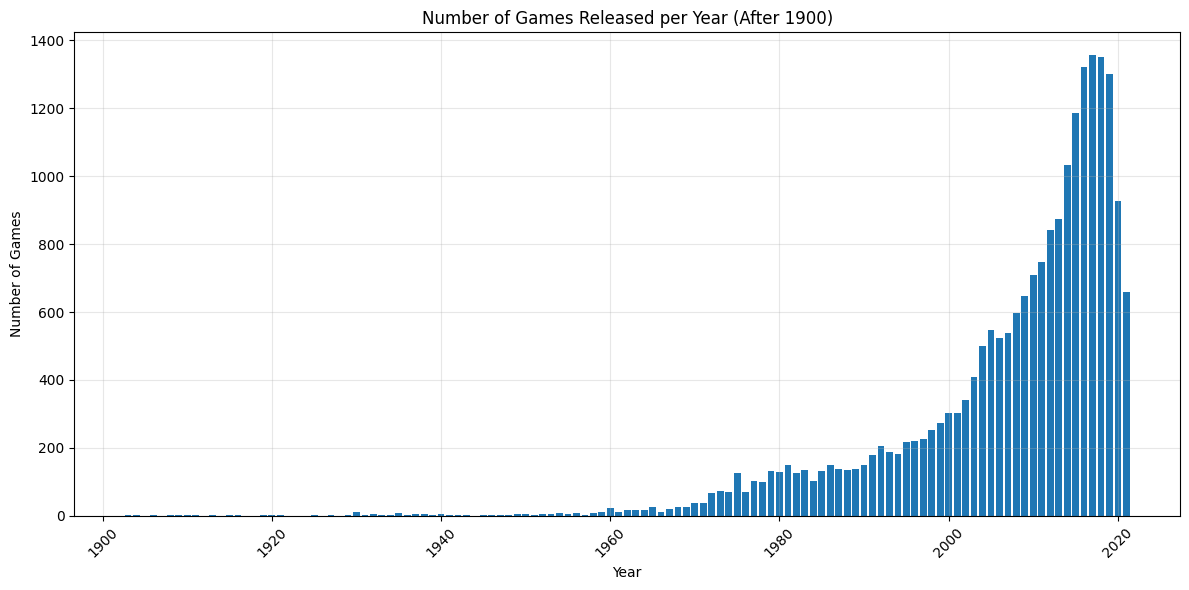

In [17]:
recent_games = bf[bf['YearPublished'] > 1900]['YearPublished'].value_counts().sort_index()

# Create the plot
plt.figure(figsize=(12, 6))
plt.bar(recent_games.index, recent_games.values)
plt.title('Number of Games Released per Year (After 1900)')
plt.xlabel('Year')
plt.ylabel('Number of Games')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Media: 1985, mediana: 2011.  
Filtro per il 1950 (da giustificare)

In [18]:
Q1 = bf['YearPublished'].quantile(0.25)
Q3 = bf['YearPublished'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 3 * IQR
upper_bound = Q3 + 3 * IQR
print(f"Lower Bound: {lower_bound}, Upper Bound: {upper_bound}")


Lower Bound: 1953.0, Upper Bound: 2065.0


In [19]:
bf = bf[bf['YearPublished'] >= 1950]

# GameWeight e ComWeight

In [20]:
bf['GameWeight'].corr(bf['ComWeight'])

np.float64(0.9972769534320508)

In [21]:
bf['GameWeight'].describe()

count    21519.000000
mean         1.987740
std          0.849206
min          0.000000
25%          1.333300
50%          2.000000
75%          2.535950
max          5.000000
Name: GameWeight, dtype: float64

In [22]:
bf['ComWeight'].describe()

count    21519.000000
mean         2.183100
std          0.861943
min          0.000000
25%          1.519450
50%          2.134100
75%          2.744100
max          5.213200
Name: ComWeight, dtype: float64

In [23]:
bf = bf.drop(columns=['GameWeight'])

## Gestione del fatto che il peso parte da 1 e non da 0:

In [24]:
bf['ComWeight'].corr(bf['ComAgeRec'])

np.float64(0.647614574219227)

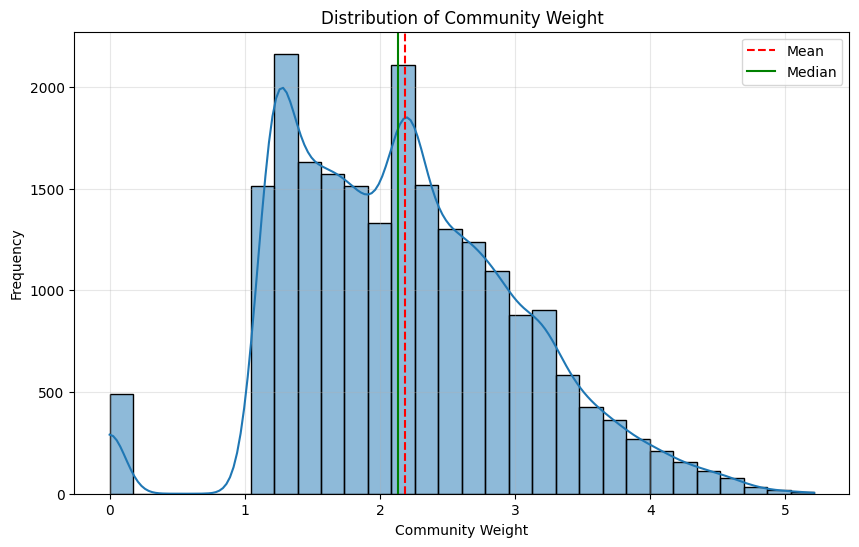

In [25]:
# distribuzione di ComWeight
plt.figure(figsize=(10, 6))
sns.histplot(bf['ComWeight'], bins=30, kde=True)
plt.title('Distribution of Community Weight')
plt.axvline(bf['ComWeight'].mean(), color='r', linestyle='--', label='Mean')
plt.axvline(bf['ComWeight'].median(), color='g', linestyle='-', label='Median')
plt.legend()
plt.xlabel('Community Weight')
plt.ylabel('Frequency')
plt.grid(True, alpha=0.3)
plt.show()

In [26]:
len(bf[bf['ComWeight']==0])

491

In [27]:
colonne_categoria = [col for col in bf.columns if col.startswith('Cat:')]

df_zero = bf[bf['ComWeight'] == 0].copy()
giochi_trovati_con_categorie = 0
for index, row in df_zero.iterrows():
    # Assumiamo che la colonna 'Name' esista
    nome = row.get('Name', f"Gioco con BGGId: {row.get('BGGId', 'ID Sconosciuto')}")
    
    categorie_trovate = []

    # 4. Controlla tutte le colonne 'Cat:' per questa riga
    for cat_col in colonne_categoria:
        if row[cat_col] == 1:
            # Pulisce il nome della categoria (es. 'Cat:War' -> 'War')
            categoria_pulita = cat_col.replace('Cat:', '')
            categorie_trovate.append(categoria_pulita)

    # 5. Stampa il risultato SOLO se sono state trovate categorie
    if categorie_trovate: # Se la lista non è vuota
        giochi_trovati_con_categorie += 1
        print(f"**{nome}** -> {', '.join(categorie_trovate)}")

print("-" * 50)
print(f"Totale giochi (ComWeight=0) trovati con categorie: {giochi_trovati_con_categorie}")
print(f"Totale giochi (ComWeight=0) senza categorie: {len(df_zero) - giochi_trovati_con_categorie}")

**Stapelei** -> Childrens
**Zingo! 1-2-3** -> Childrens
**Breaking Point** -> Childrens
**Fendo** -> Abstract
**Kaleidos Junior** -> Childrens
**The Terminator: CCG** -> CGS
**Isi** -> Abstract
**Greener** -> Abstract
**Babel** -> Abstract
**Kangaroo: The Jumping Game** -> Abstract
**Dragon Chess** -> Abstract
**Hasp** -> Family
**The Touch** -> Childrens
**Sequence Num6ers** -> Abstract
**High Five!** -> Abstract
**Sleepers** -> Abstract
**Pandabo** -> Childrens
**Napoleon Retreats: Campaign in France, Part II** -> War
**Junta** -> Abstract
**Monopoly Junior: Travel Edition** -> Childrens
**Alfredo's Food Fight** -> Childrens
**Team Yankee** -> War
**Monopoly Junior: Dig 'n Dinos** -> Childrens
**A Song of Ice & Fire: Tabletop Miniatures Game – Free Folk Starter Set** -> War
**Masters of the Universe 3-D Action Game** -> Childrens
**IQube** -> Abstract
**Warhammer: The Game of Fantasy Battles (7th Edition)** -> War
--------------------------------------------------
Totale giochi (ComW

Gestione dei ComWeight che sono maggiori di 5

In [28]:
# Assumiamo che 'bf' sia il tuo DataFrame principale
# e che 'ComWeight' contenga ancora gli 0.0

# 1. Identifica tutte le colonne Categoria
colonne_categoria = [col for col in bf.columns if col.startswith('Cat:')]

# 2. Filtra il DataFrame per ComWeight = 0
df_zero_weight = bf[bf['ComWeight'] == 0].copy()

# 3. Crea la "Lista Master" (inizialmente vuota)
# Questa lista raccoglierà TUTTE le categorie trovate
lista_master_categorie = [] 

# 4. Itera sulle righe filtrate
for index, row in df_zero_weight.iterrows():
    
    # Controlla tutte le colonne 'Cat:' per questa riga
    for cat_col in colonne_categoria:
        if row[cat_col] == 1:
            # Pulisce il nome della categoria (es. 'Cat:War' -> 'War')
            categoria_pulita = cat_col.replace('Cat:', '')
            
            # Aggiunge la categoria trovata alla Lista Master
            lista_master_categorie.append(categoria_pulita)

# --- ORA ESEGUI IL TUO CODICE SULLA LISTA MASTER ---

# 5. Inizializza il dizionario
diz = {}

# 6. Itera sulla Lista Master e conta
for categoria in lista_master_categorie:
    if categoria in diz:
        diz[categoria] += 1
    else:
        diz[categoria] = 1

print("Conteggio finale delle categorie (dai 491 giochi con ComWeight=0):")
print(diz)


Conteggio finale delle categorie (dai 491 giochi con ComWeight=0):
{'Childrens': 10, 'Abstract': 11, 'CGS': 1, 'Family': 1, 'War': 4}


In [29]:
#describe di NumWeightVotes quando ComWeight è 0
bf[bf['ComWeight'] == 0]['NumWeightVotes'].describe()


count    491.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
Name: NumWeightVotes, dtype: float64

In [30]:
# NumUserRatings quando ComWeight è 0
bf[bf['ComWeight'] == 0]['NumUserRatings'].mean()

np.float64(47.02851323828921)

In [31]:
#ComAgeRec quando ComWeight è 0
bf[bf['ComWeight'] == 0]['ComAgeRec'].mean()

np.float64(8.035353535353535)

In [32]:
#media di MfgPlayTime e ComMinPlayTime quando ComWeight è 0
bf[bf['ComWeight'] == 0][['MfgPlaytime', 'ComMinPlaytime']].mean()

MfgPlaytime       49.879837
ComMinPlaytime    28.146640
dtype: float64

In [33]:
df_zero = bf[bf['ComWeight'] == 0]
df_rated = bf[bf['ComWeight'] > 0]
print("Età media (Giochi 0-Weight):", df_zero['ComAgeRec'].mean())
print("Età media (Giochi Votati):", df_rated['ComAgeRec'].mean())

print("Tempo Gioco Min (Giochi 0-Weight):", df_zero['ComMinPlaytime'].mean())
print("Tempo Gioco Min (Giochi Votati):", df_rated['ComMinPlaytime'].mean())


Età media (Giochi 0-Weight): 8.035353535353535
Età media (Giochi Votati): 10.054392635973326
Tempo Gioco Min (Giochi 0-Weight): 28.14663951120163
Tempo Gioco Min (Giochi Votati): 65.1006277344493


Non c'è un modo per gestire i valori di ComWeight = 0 (riguardare le varie prove, nel caso metterle se interessanti)  
In statistica, a volte i dati mancano per un motivo preciso. Su BGG, gli utenti "hardcore" votano il peso. Se un gioco non riceve voti sul peso, spesso è perché è considerato troppo banale o semplice per meritare una discussione sulla complessità. Lo zero qui non è casuale: è un segnale di semplicità estrema o irrilevanza.

In [34]:
bf['ComWeight'] = bf['ComWeight'].replace(0, 1.0)

In [35]:
# imposta a 5 i valori di ComWeight > 5
bf.loc[bf['ComWeight'] > 5, 'ComWeight'] = 5

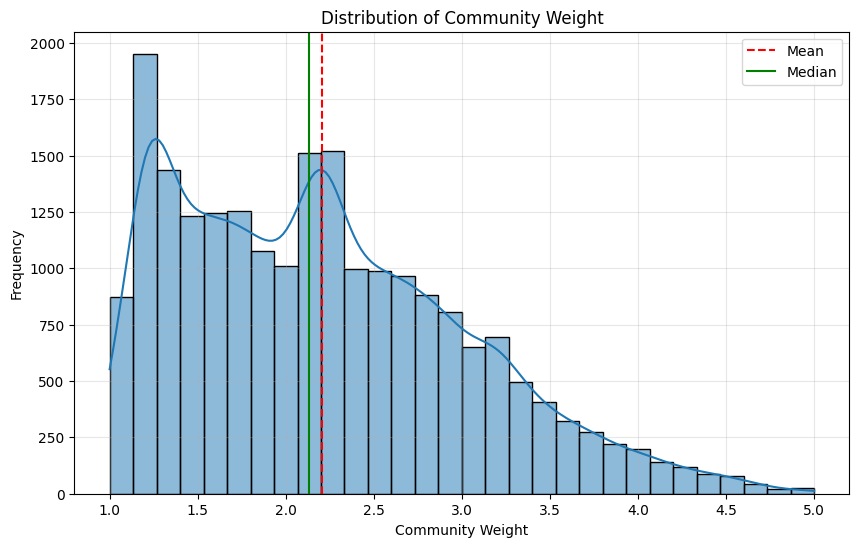

In [36]:
# distribuzione di ComWeight
plt.figure(figsize=(10, 6))
sns.histplot(bf['ComWeight'], bins=30, kde=True)
plt.title('Distribution of Community Weight')
plt.axvline(bf['ComWeight'].mean(), color='r', linestyle='--', label='Mean')
plt.axvline(bf['ComWeight'].median(), color='g', linestyle='-', label='Median')
plt.legend()
plt.xlabel('Community Weight')
plt.ylabel('Frequency')
plt.grid(True, alpha=0.3)
plt.show()

# MinPlayers e MaxPlayers

In [37]:
bf['MinPlayers'].describe()

count    21519.000000
mean         2.005809
std          0.691868
min          0.000000
25%          2.000000
50%          2.000000
75%          2.000000
max         10.000000
Name: MinPlayers, dtype: float64

In [38]:
bf['MaxPlayers'].describe()

count    21519.000000
mean         5.696175
std         15.075926
min          0.000000
25%          4.000000
50%          4.000000
75%          6.000000
max        999.000000
Name: MaxPlayers, dtype: float64

Assegnare a MinPlayers 1 quando il valore è 0:

In [39]:
#Assegnare a MinPlayers 1 quando il valore è 0 mantenendo il valore intero:
bf.loc[bf['MinPlayers'] == 0, 'MinPlayers'] = 1

In [40]:
# Count instances where MinPlayers > MaxPlayers
inconsistent_count = len(bf[bf['MinPlayers'] > bf['MaxPlayers']])
print(f"Number of games where MinPlayers > MaxPlayers: {inconsistent_count}")

# Display these cases if any exist
if inconsistent_count > 0:
    print("\nGames with inconsistent player counts:")
    inconsistent_cases = bf[bf['MinPlayers'] > bf['MaxPlayers']][['Name', 'MinPlayers', 'MaxPlayers']]
    display(inconsistent_cases)

Number of games where MinPlayers > MaxPlayers: 155

Games with inconsistent player counts:


,Name,MinPlayers,MaxPlayers
206,Bet Your Brain,2,0
268,Connection Games,1,0
604,Flying Lead,2,0
640,Sushi Bar,1,0
827,Pub Trivia,3,0
...,...,...,...
21082,BattleTech,2,0
21201,La Bérézina 1812,2,0
21243,Board and Table Games from Many Civilizations,1,0
21246,Ghost Hunt,1,0


## Distribuzione dei MaxPlayers

In [41]:
# Count games for each MaxPlayers value between 0 and 20
player_counts = bf[bf['MaxPlayers'] <= 20]['MaxPlayers'].value_counts().sort_index()

print("Distribution of games by maximum players (0-20):")
for players, count in player_counts.items():
    print(f"{players} players: {count} games")

print(f"\nTotal games with 0-20 max players: {player_counts.sum()}")

Distribution of games by maximum players (0-20):
0 players: 155 games
1 players: 360 games
2 players: 4257 games
3 players: 282 games
4 players: 6765 games
5 players: 3028 games
6 players: 3942 games
7 players: 322 games
8 players: 1213 games
9 players: 72 games
10 players: 401 games
11 players: 9 games
12 players: 242 games
13 players: 6 games
14 players: 11 games
15 players: 43 games
16 players: 62 games
17 players: 6 games
18 players: 11 games
20 players: 63 games

Total games with 0-20 max players: 21250


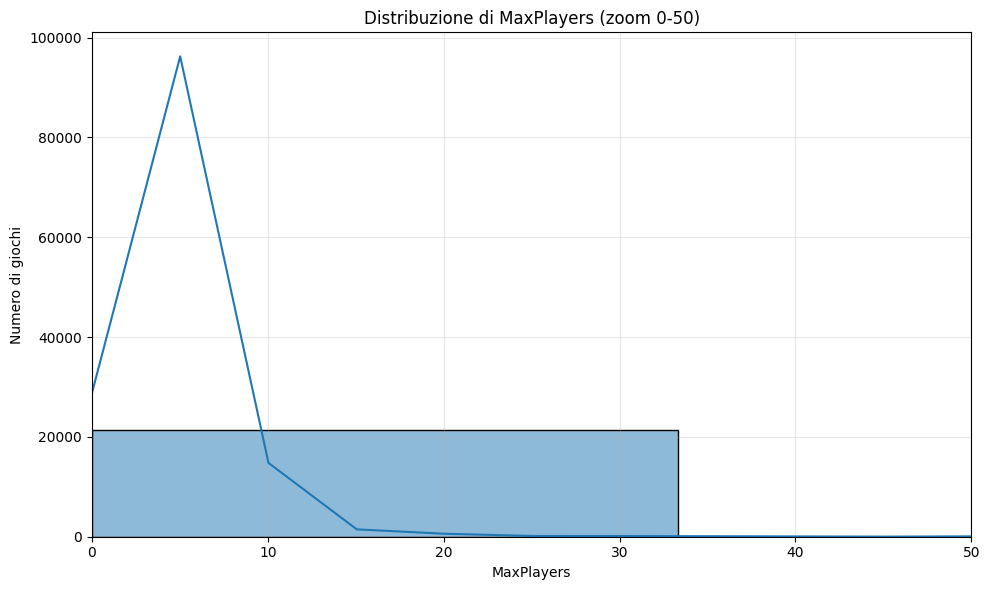

In [42]:
plt.figure(figsize=(10, 6))
sns.histplot(bf['MaxPlayers'], bins=30, kde=True)
plt.title('Distribuzione di MaxPlayers (zoom 0-50)')
plt.xlabel('MaxPlayers')
plt.ylabel('Numero di giochi')
plt.xlim(0, 50)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Il rettangolo mostra l'area della densità di probabilità stimata (KDE) tracciata dal grafico.

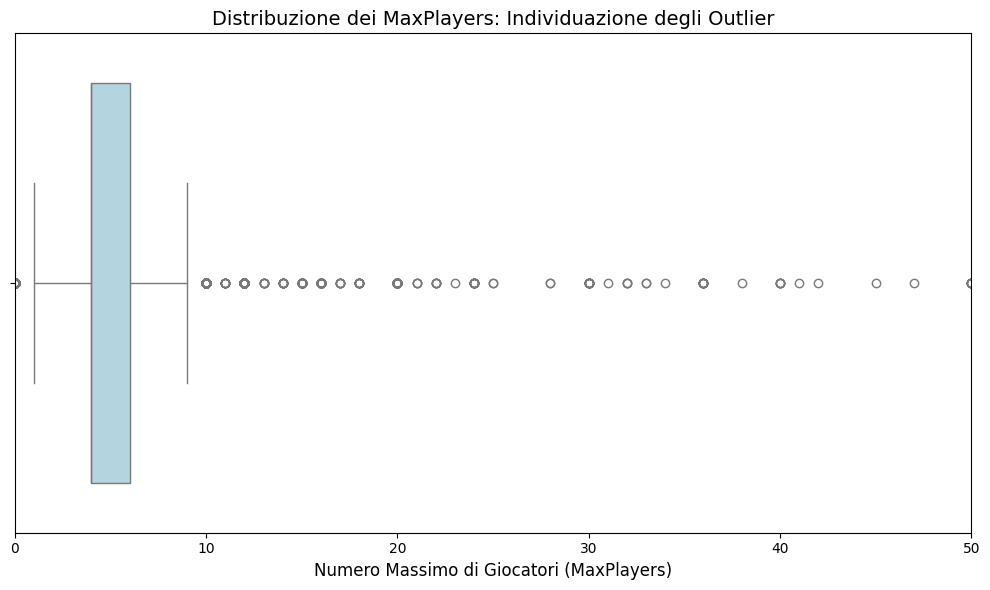

In [43]:
plt.figure(figsize=(10, 6))
# Box plot per MaxPlayers
sns.boxplot(
    data=bf, 
    x='MaxPlayers', 
    color='lightblue',
    orient='h' # Grafico orizzontale
) 
plt.title('Distribuzione dei MaxPlayers: Individuazione degli Outlier', fontsize=14)
plt.xlabel('Numero Massimo di Giocatori (MaxPlayers)', fontsize=12)
plt.xlim(0, 50) # Mantiene lo zoom da 0 a 50
plt.tight_layout()
plt.show()

In [44]:
equal_players = len(bf[bf['MinPlayers'] == bf['MaxPlayers']])
print(f"Number of games where MinPlayers equals MaxPlayers: {equal_players}")
print(f"Percentage: {(equal_players/len(bf)*100):.2f}%")

# Optional: Display some examples
examples = bf[bf['MinPlayers'] == bf['MaxPlayers']].sample(5)[['Name', 'MinPlayers', 'MaxPlayers']]
print("\nExample games:")
display(examples)

Number of games where MinPlayers equals MaxPlayers: 4018
Percentage: 18.67%

Example games:


,Name,MinPlayers,MaxPlayers
14389,KRASH!,2,2
2751,Normandie 1944,2,2
12747,Drako: Dragon & Dwarves,2,2
15664,The Reef,2,2
12454,The Normandy Campaign,2,2


Quando MinPlayers = 1, MaxPlayers è al massimo 4, quindi posso imputargli quel valore, essendo 4 anche la mediana, che è un indice robusto

In [45]:
# quando MinPlayers maggiore di MaxPlayers, vedere il numero di MaxPlayers
inconsistent_games = bf[bf['MinPlayers'] > bf['MaxPlayers']]
display(inconsistent_games[['Name', 'MinPlayers', 'MaxPlayers']])


,Name,MinPlayers,MaxPlayers
206,Bet Your Brain,2,0
268,Connection Games,1,0
604,Flying Lead,2,0
640,Sushi Bar,1,0
827,Pub Trivia,3,0
...,...,...,...
21082,BattleTech,2,0
21201,La Bérézina 1812,2,0
21243,Board and Table Games from Many Civilizations,1,0
21246,Ghost Hunt,1,0


Essendo che quando MinPlayers è maggiore di MaxPlayers, il massimo di MinPlayers è 4, assegno 4 a MaxPlayers

In [46]:
# 1. Filtra i dati incoerenti
dati_MinP_MaxP = bf[bf['MinPlayers'] > bf['MaxPlayers']]
massimo_MinP = dati_MinP_MaxP['MinPlayers'].max()
massimo_MinP

np.int64(4)

In [47]:
#assegnare il valore massimo a MaxPlayers quando MinPlayers è maggiore di MaxPlayers
bf.loc[bf['MinPlayers'] > bf['MaxPlayers'], 'MaxPlayers'] = massimo_MinP

Gestire MaxPlayers -> quando sono valori molto alti (guardare distribuzione) e quando il valore è minore dei MinPlayer (ovviamente precedenza a MinPlayers)

Per valori maggiori di 50 giocatori si assegna un valore arbitrario di 50

In [48]:
 #Se MaxPlayers è maggiore di 50, assegna 50
bf.loc[bf['MaxPlayers'] > 50, 'MaxPlayers'] = 50

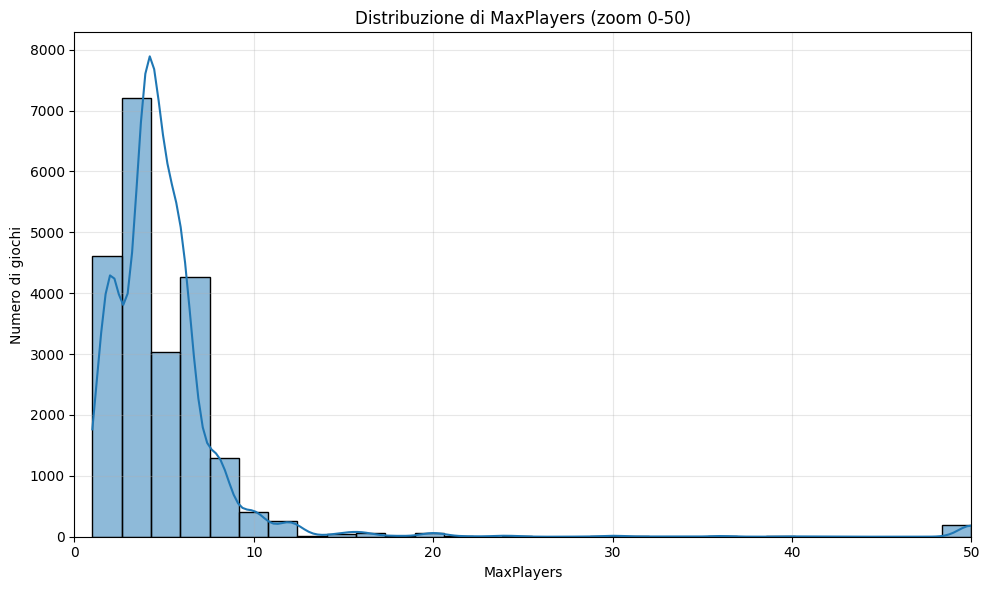

In [49]:
plt.figure(figsize=(10, 6))
sns.histplot(bf['MaxPlayers'], bins=30, kde=True)
plt.title('Distribuzione di MaxPlayers (zoom 0-50)')
plt.xlabel('MaxPlayers')
plt.ylabel('Numero di giochi')
plt.xlim(0, 50)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ComAgeRec

In [50]:
bf['ComAgeRec'].describe()

count    16092.000000
mean        10.046112
std          3.259259
min          2.000000
25%          8.000000
50%         10.000000
75%         12.000000
max         21.000000
Name: ComAgeRec, dtype: float64

In [51]:
bf['ComAgeRec'].isna().sum()

np.int64(5427)

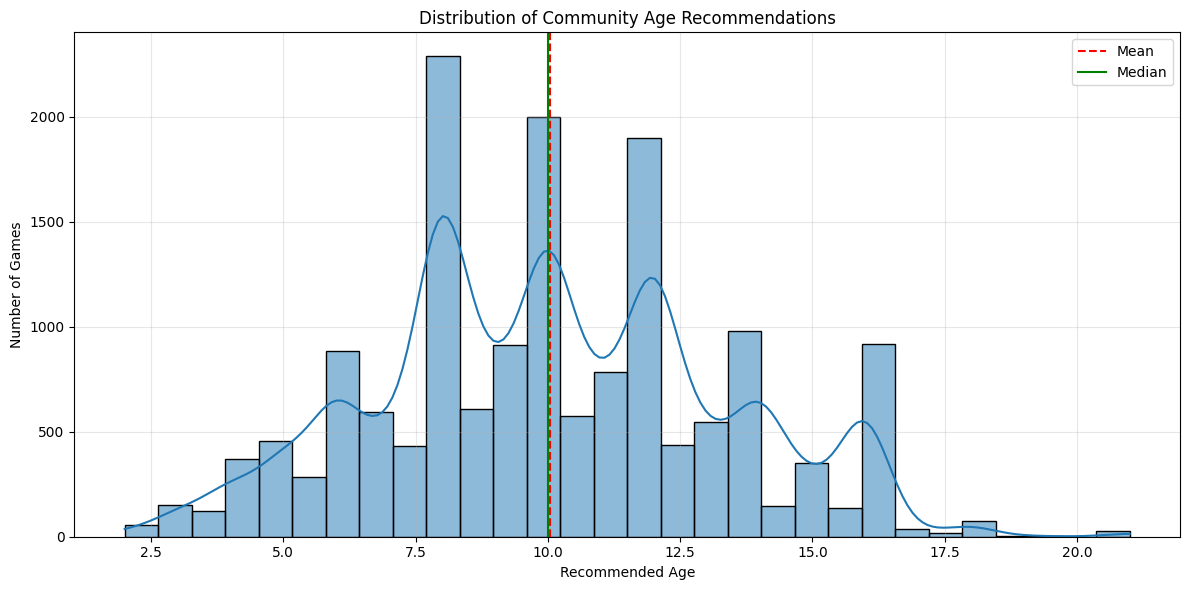

In [52]:
# Analyze ComAgeRec distribution
plt.figure(figsize=(12, 6))
sns.histplot(data=bf[bf['ComAgeRec'].notna()], x='ComAgeRec', bins=30, kde=True)
plt.axvline(bf['ComAgeRec'].mean(), color='r', linestyle='--', label='Mean')
plt.axvline(bf['ComAgeRec'].median(), color='g', linestyle='-', label='Median')
plt.legend()
plt.title('Distribution of Community Age Recommendations')
plt.xlabel('Recommended Age')
plt.ylabel('Number of Games')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [53]:
#vedere i giochi con ComAgeRec = Nan, vedere quanti appartengono alla categoria Cat:War
giochi_con_age_nan = bf[bf['ComAgeRec'].isna()]
giochi_con_age_nan_war = giochi_con_age_nan[giochi_con_age_nan['Cat:War'] == 1]
print(f"Number of games with ComAgeRec = NaN: {len(giochi_con_age_nan)}")
print(f"Number of games with ComAgeRec = NaN and in Cat:War: {len(giochi_con_age_nan_war)}")



Number of games with ComAgeRec = NaN: 5427
Number of games with ComAgeRec = NaN and in Cat:War: 687


In [54]:
#ComAgeRec media dei giochi in Cat:War
com_age_rec_war_mean = bf[bf['Cat:War'] == 1]['ComAgeRec'].mean()
com_age_rec_war_median = bf[bf['Cat:War'] == 1]['ComAgeRec'].median()
com_age_rec_war_mean, com_age_rec_war_median

(np.float64(13.672316944502374), np.float64(14.0))

In [55]:
#Ai giochi con Cat:War, essendo giochi mediamente pensati per un pubblico più adulto, assegno un valore di 14 anni di comAgeRec, 
#essendo 14 sia la mediana sia la media arrotondata.
bf.loc[(bf['Cat:War'] == 1) & (bf['ComAgeRec'].isna()), 'ComAgeRec'] = 14

In [56]:
#assegnare a ComAgeRec = Nan il valore medio
bf.loc[bf['ComAgeRec'].isna(), 'ComAgeRec'] = bf['ComAgeRec'].mean()

In [57]:
#arrotonda i valori di ComAgeRec a interi
bf['ComAgeRec'] = bf['ComAgeRec'].round().astype(int)

# LanguageEase

In [58]:
bf['LanguageEase'].isna().sum()

np.int64(5775)

In [59]:
bf['LanguageEase'].describe()

count    15744.000000
mean       217.297682
std        236.061456
min          1.000000
25%         26.000000
50%        141.000000
75%        352.000000
max       1757.000000
Name: LanguageEase, dtype: float64

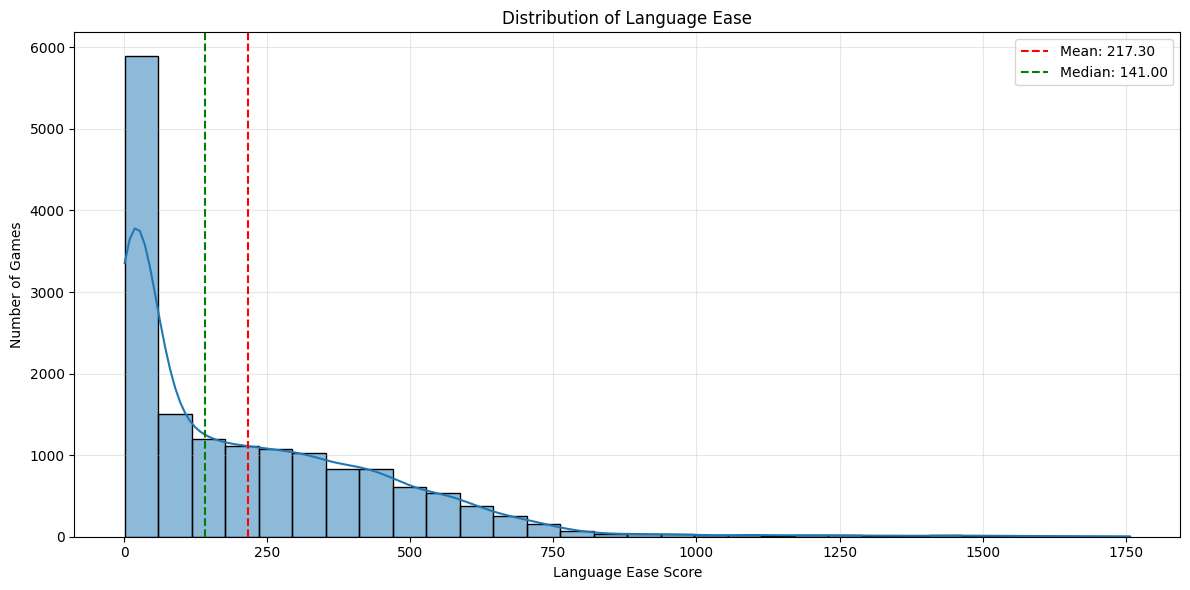

count    15744.000000
mean       217.297682
std        236.061456
min          1.000000
25%         26.000000
50%        141.000000
75%        352.000000
max       1757.000000
Name: LanguageEase, dtype: float64

In [60]:
# Create a histogram plot for LanguageEase
plt.figure(figsize=(12, 6))

# Plot the histogram with KDE
sns.histplot(data=bf[bf['LanguageEase'].notna()], x='LanguageEase', bins=30, kde=True)

# Customize the plot
plt.title('Distribution of Language Ease')
plt.xlabel('Language Ease Score')
plt.ylabel('Number of Games')
plt.grid(True, alpha=0.3)

# Add mean and median lines
mean = bf['LanguageEase'].mean()
median = bf['LanguageEase'].median()
plt.axvline(mean, color='red', linestyle='--', label=f'Mean: {mean:.2f}')
plt.axvline(median, color='green', linestyle='--', label=f'Median: {median:.2f}')

plt.legend()
plt.tight_layout()
plt.show()
bf['LanguageEase'].describe()

In [61]:
# Count games with LanguageEase values between 0-500
low_language = len(bf[(bf['LanguageEase'] >= 0) & (bf['LanguageEase'] <= 500)])

# Count games with LanguageEase values above 500
high_language = len(bf[bf['LanguageEase'] > 500])

print(f"Games with LanguageEase between 0 and 500: {low_language}")
print(f"Games with LanguageEase above 500: {high_language}")

Games with LanguageEase between 0 and 500: 13837
Games with LanguageEase above 500: 1907


In [62]:
percentuale_nulli_languageEase = bf['LanguageEase'].isna().mean() * 100
print(f"Percentuale di valori nulli in LanguageEase: {percentuale_nulli_languageEase:.2f}%")

Percentuale di valori nulli in LanguageEase: 26.84%


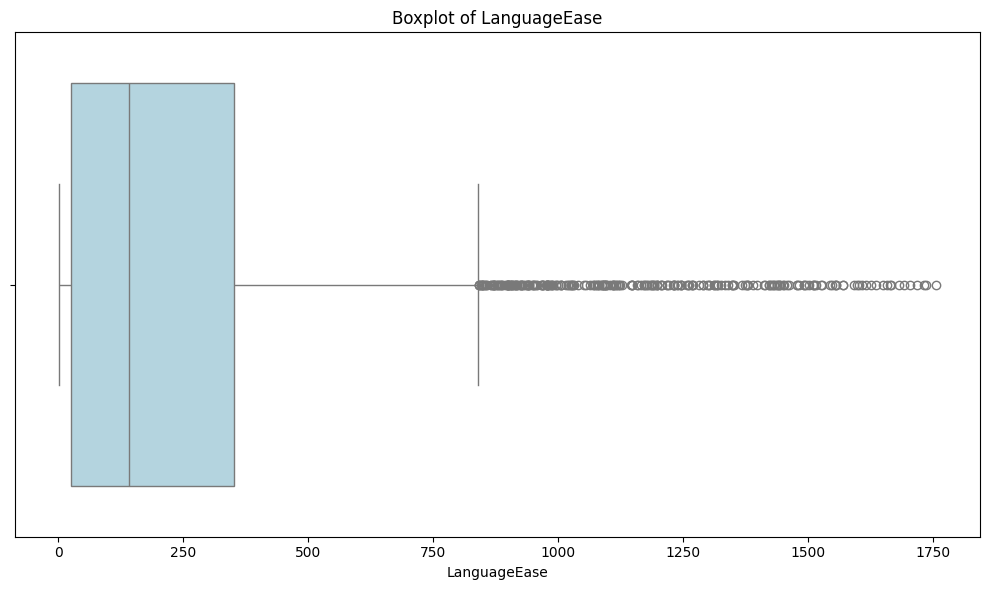

In [63]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=bf, x='LanguageEase', color='lightblue')
plt.title('Boxplot of LanguageEase')
plt.xlabel('LanguageEase')
plt.tight_layout()
plt.show()

In [64]:
bf['LanguageEase'].min()

np.float64(1.0)

In [65]:
#language ease in scala logaritmica
bf['LanguageEase'] = np.log1p(bf['LanguageEase']).fillna(bf['LanguageEase'].min())


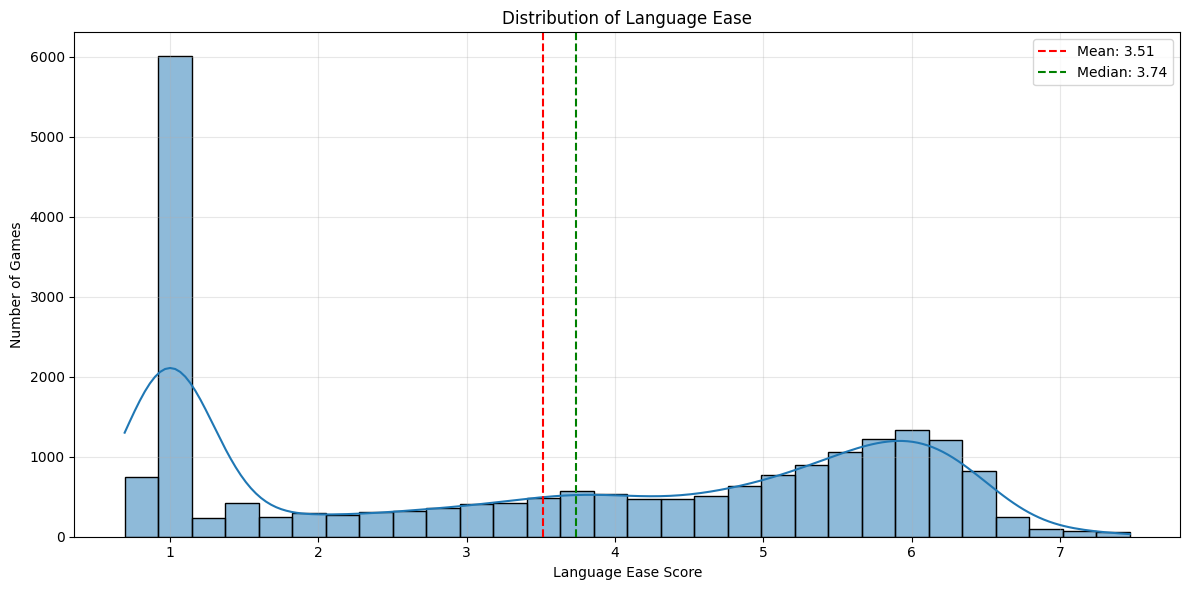

count    21519.000000
mean         3.513793
std          2.126887
min          0.693147
25%          1.000000
50%          3.737670
75%          5.605802
max          7.471932
Name: LanguageEase, dtype: float64

In [66]:
# Create a histogram plot for LanguageEase
plt.figure(figsize=(12, 6))

# Plot the histogram with KDE
sns.histplot(data=bf[bf['LanguageEase'].notna()], x='LanguageEase', bins=30, kde=True)

# Customize the plot
plt.title('Distribution of Language Ease')
plt.xlabel('Language Ease Score')
plt.ylabel('Number of Games')
plt.grid(True, alpha=0.3)

# Add mean and median lines
mean = bf['LanguageEase'].mean()
median = bf['LanguageEase'].median()
plt.axvline(mean, color='red', linestyle='--', label=f'Mean: {mean:.2f}')
plt.axvline(median, color='green', linestyle='--', label=f'Median: {median:.2f}')

plt.legend()
plt.tight_layout()
plt.show()
bf['LanguageEase'].describe()

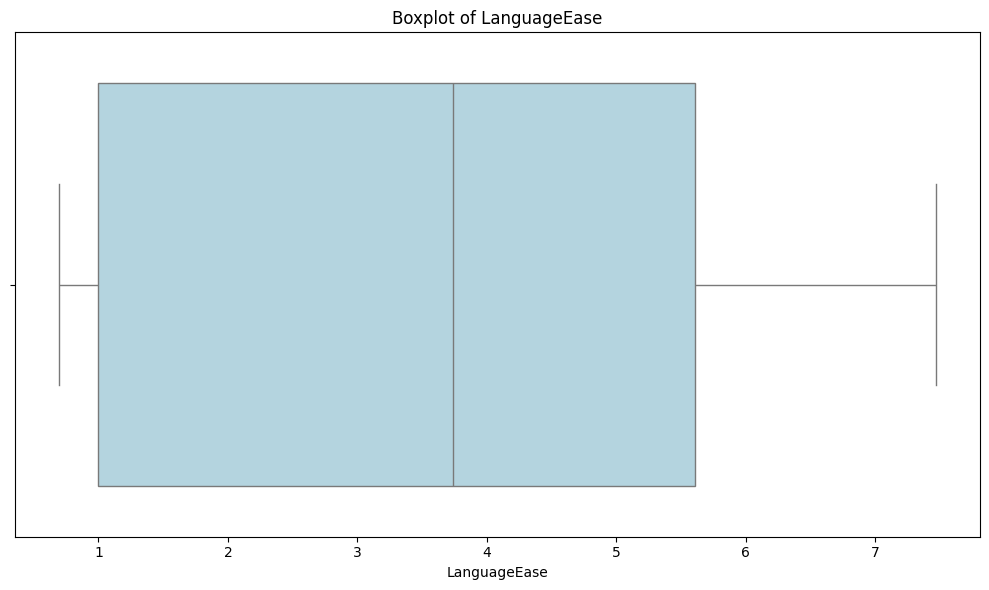

In [67]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=bf, x='LanguageEase', color='lightblue')
plt.title('Boxplot of LanguageEase')
plt.xlabel('LanguageEase')
plt.tight_layout()
plt.show()

Gestione LanguageEase: non so come gestirlo :D

###HANDLING COMMINPLAYTIME, COMMAXPLAYTIME E MFGPLAYTIME

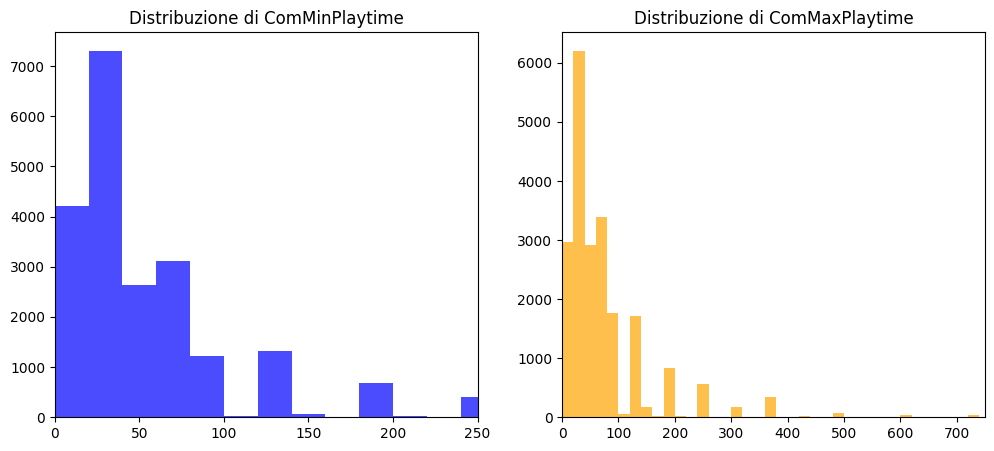

In [68]:
#visualizzo la distribuzione di comminplaytime e commaxplaytime
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(bf['ComMinPlaytime'], bins=3000, color='blue', alpha=0.7)
plt.title('Distribuzione di ComMinPlaytime')
plt.xlim(0,250)
plt.subplot(1, 2, 2)
plt.hist(bf['ComMaxPlaytime'], bins=3000, color='orange', alpha=0.7)
plt.title('Distribuzione di ComMaxPlaytime')
plt.xlim(0,750)
plt.show()

In [69]:
#vedo quanti giochi hanno ComMinPlaytime uguale a 0
com_min_playtime_0 = bf[bf['ComMinPlaytime'] == 0]
len(com_min_playtime_0)

612

In [70]:
#vedo la media di ComMinPlaytime e ComMaxPlaytime
print(bf['ComMinPlaytime'].mean())
print(bf['ComMaxPlaytime'].mean())
print(bf["MfgPlaytime"].mean())

64.25744690738418
91.52349086853478
91.52349086853478


In [71]:
bf["ComMaxPlaytime"].describe()

count    21519.000000
mean        91.523491
std        534.553601
min          0.000000
25%         30.000000
50%         45.000000
75%         90.000000
max      60000.000000
Name: ComMaxPlaytime, dtype: float64

In [72]:
bf["ComMinPlaytime"].describe()

count    21519.000000
mean        64.257447
std        448.040319
min          0.000000
25%         20.000000
50%         30.000000
75%         60.000000
max      60000.000000
Name: ComMinPlaytime, dtype: float64

In [73]:
#vedo qual è il gioco con ComMinPlaytime più alto
game_max_comminplaytime = bf[["Name", "ComMinPlaytime","ComMaxPlaytime"]][bf["ComMinPlaytime"] == bf["ComMinPlaytime"].max()]
game_max_comminplaytime

,Name,ComMinPlaytime,ComMaxPlaytime
4349,The Campaign for North Africa: The Desert War ...,60000,60000


In [74]:
#correlazione tra commaxplaytime e mfgplaytime
bf['ComMaxPlaytime'].corr(bf['MfgPlaytime'])

np.float64(1.0)

In [75]:
#In virtù della correlazione di 1 tra commaxplaytime e mfgplaytime, droppo la colonna mfgplaytime
bf = bf.drop(columns=['MfgPlaytime'])

In [76]:
#vedo quanti giochi hanno ComMaxPlaytime uguale a 0
com_max_playtime_0 = bf[bf['ComMaxPlaytime'] == 0]
len(com_max_playtime_0)


739

In [77]:
#vedo il minimo di comminplaytime escludendo gli 0
bf_nonzero_comminplaytime = bf[bf['ComMinPlaytime'] > 0]
bf_nonzero_comminplaytime['ComMinPlaytime'].min()


np.int64(1)

In [78]:
#vedo quanti giochi hanno ComMaxPlaytime uguale a 0
com_min_playtime_0 = bf[bf['ComMinPlaytime'] == 0]
len(com_min_playtime_0)

612

In [79]:
#vedo quanti giochi hanno comminplaytime e commaxplaytime uguale a 0
com_playtime_0 = bf[(bf['ComMinPlaytime'] == 0) & (bf['ComMaxPlaytime'] == 0)]
len(com_playtime_0)

593

In [80]:
#vedo quali giochi hanno comminplaytime maggiore di commaxplaytime
comminplaytime_greater = bf[bf['ComMinPlaytime'] > bf['ComMaxPlaytime']]
len(comminplaytime_greater)

150

In [81]:
#visualizzo i giochi con comminplaytime maggiore di commaxplaytime
comminplaytime_greater[["Name", "ComMinPlaytime", "ComMaxPlaytime"]]

,Name,ComMinPlaytime,ComMaxPlaytime
100,Miskatonic School for Boys,45,0
168,Polyhedral Park Planner,30,0
176,Artifact Stack,20,0
793,Würfel-WG,35,0
1068,Monster Kit,10,0
...,...,...,...
21315,Tue Fourre Marie... et pire encore!,30,0
21400,Maigo-Neko,30,0
21508,Götterdämmerung,45,0
21561,Der Schatz der 13 Inseln,20,0


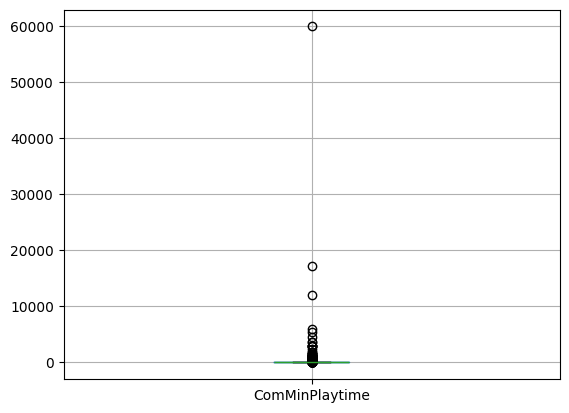

In [82]:
#boxplot del comminplaytime
boxplot = bf.boxplot(column=['ComMinPlaytime'])

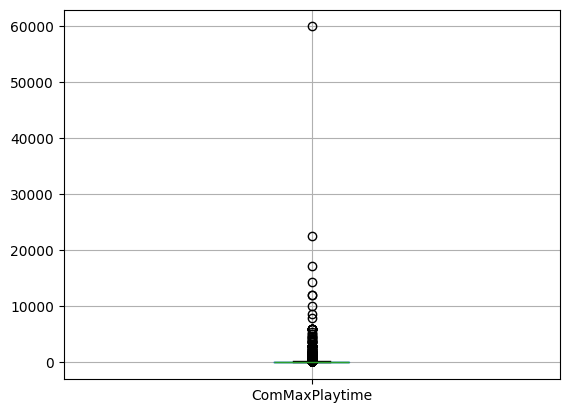

In [83]:
boxplot = bf.boxplot(column=['ComMaxPlaytime'])

In [84]:
Q1 = bf['ComMinPlaytime'].quantile(0.25)
Q3 = bf['ComMinPlaytime'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"lower bound: {lower_bound}, upper bound: {upper_bound}")

comminplaytime_outliers = bf[(bf['ComMinPlaytime'] < lower_bound) | (bf['ComMinPlaytime'] > upper_bound)]
print(f"Number of outliers in comminplaytime: {len(comminplaytime_outliers)}")

lower bound: -40.0, upper bound: 120.0
Number of outliers in comminplaytime: 1706


In [85]:
Q1 = bf['ComMaxPlaytime'].quantile(0.25)
Q3 = bf['ComMaxPlaytime'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"lower bound: {lower_bound}, upper bound: {upper_bound}")

commaxplaytime_outliers = bf[(bf['ComMaxPlaytime'] < lower_bound) | (bf['ComMaxPlaytime'] > upper_bound)]
print(f"Number of outliers in commaxplaytime: {len(commaxplaytime_outliers)}")

lower bound: -60.0, upper bound: 180.0
Number of outliers in commaxplaytime: 1461


In [86]:
#Assegno ai giochi con comminplaytime uguale a 0, il valore di comminplaytime uguale a 1
bf.loc[bf['ComMinPlaytime'] == 0, 'ComMinPlaytime'] = 1

In [87]:
#Controllo mediana e moda di commaxplaytime
print(bf['ComMaxPlaytime'].median())
print(bf['ComMaxPlaytime'].mode())


45.0
0    30
Name: ComMaxPlaytime, dtype: int64


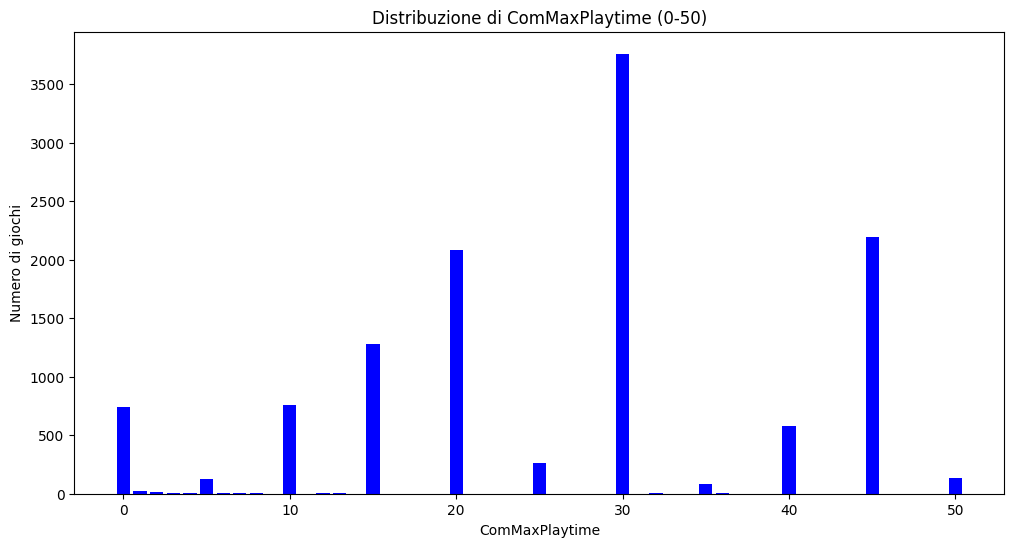

In [88]:
#Faccio un bar chart dei valori di commaxplaytime da 0 a 50
commaxplaytime_counts = bf['ComMaxPlaytime'][bf['ComMaxPlaytime'] <= 50].value_counts().sort_index()
plt.figure(figsize=(12, 6))
plt.bar(commaxplaytime_counts.index, commaxplaytime_counts.values, color='blue')
plt.title('Distribuzione di ComMaxPlaytime (0-50)')
plt.xlabel('ComMaxPlaytime')
plt.ylabel('Numero di giochi')
plt.show()


In [89]:
#Ai giochi con commaxplaytime uguale a 0, assegno la mediana di commaxplaytime
median_commaxplaytime = bf['ComMaxPlaytime'].median()
bf.loc[bf['ComMaxPlaytime'] == 0, 'ComMaxPlaytime'] = median_commaxplaytime

In [90]:
bf[bf['ComMaxPlaytime'] == 0]


,BGGId,Name,YearPublished,ComWeight,MinPlayers,MaxPlayers,ComAgeRec,LanguageEase,BestPlayers,GoodPlayers,...,Rank:childrensgames,Cat:Thematic,Cat:Strategy,Cat:War,Cat:Family,Cat:CGS,Cat:Abstract,Cat:Party,Cat:Childrens,Rating


In [91]:
import numpy as np
bf["ComMinPlaytime"] = np.log1p(bf["ComMinPlaytime"])
bf["ComMinPlaytime"].head(100)

0      3.433987
1      2.772589
2      3.433987
3      3.044522
4      2.772589
         ...   
97     4.795791
98     3.044522
99     2.397895
100    3.828641
101    4.110874
Name: ComMinPlaytime, Length: 100, dtype: float64

In [92]:
bf["ComMaxPlaytime"] = np.log1p(bf["ComMaxPlaytime"])
bf["ComMaxPlaytime"].head(100)

0      3.433987
1      3.044522
2      5.017280
3      3.044522
4      3.044522
         ...   
97     4.795791
98     3.433987
99     2.772589
100    3.828641
101    4.795791
Name: ComMaxPlaytime, Length: 100, dtype: float64

In [93]:
game_max_comminplaytime

,Name,ComMinPlaytime,ComMaxPlaytime
4349,The Campaign for North Africa: The Desert War ...,60000,60000


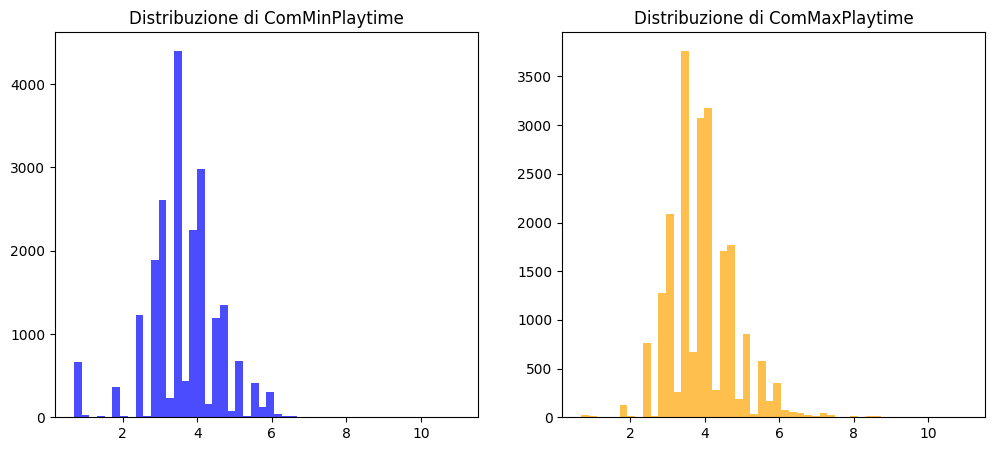

In [94]:
#Visualizzo di nuovo la distribuzione dopo la normalizzazione logaritmica
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(bf['ComMinPlaytime'], bins=50, color='blue', alpha=0.7)
plt.title('Distribuzione di ComMinPlaytime')
plt.subplot(1, 2, 2)
plt.hist(bf['ComMaxPlaytime'], bins=50, color='orange', alpha=0.7)
plt.title('Distribuzione di ComMaxPlaytime')
plt.show()

In [95]:
#Calcolo la distanza percentuale media tra le due colonne comminplaytime e commaxplaytime
bf['perc_distance_playtime'] = (
    (bf['ComMinPlaytime'] - bf['ComMaxPlaytime']).abs() /
    ((bf['ComMinPlaytime'] + bf['ComMaxPlaytime']) / 2)
) * 100

media_distanza = bf['perc_distance_playtime'].mean()

media_distanza

np.float64(10.32728982081721)

In [96]:
#Assegno ai giochi con comminplaytime maggiore di commaxplaytime, il valore di commaxplaytime uguale a comminplaytime maggiorato
#della media della distanza percentuale calcolata in precedenza
bf.loc[bf['ComMinPlaytime'] > bf['ComMaxPlaytime'], 'ComMaxPlaytime'] = \
    bf['ComMinPlaytime'] + (bf['ComMinPlaytime'] * media_distanza / 100)

In [97]:
#controllo i giochi con comminplaytime maggiore di commaxplaytime
comminplaytime_greater = bf[bf['ComMinPlaytime'] > bf['ComMaxPlaytime']]
len(comminplaytime_greater)

0

In [98]:
#Ricontrollo gli outliers del comminplaytime con la distanza interquartile dopo la normalizzazione logaritmica

Q1 = bf['ComMinPlaytime'].quantile(0.25)
Q3 = bf['ComMinPlaytime'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 2.5 * IQR
upper_bound = Q3 + 2.5 * IQR

print(f"lower bound: {lower_bound}, upper bound: {upper_bound}")

comminplaytime_outliers = bf[(bf['ComMinPlaytime'] < lower_bound) | (bf['ComMinPlaytime'] > upper_bound)]
print(f"Number of outliers in comminplaytime: {len(comminplaytime_outliers)}")

comminplaytime_below_lower = bf[bf['ComMinPlaytime'] < lower_bound]
print(len(comminplaytime_below_lower))

lower bound: 0.3786438715987024, upper bound: 6.776752430298032
Number of outliers in comminplaytime: 37
0


In [99]:
#Ricontrollo gli outliers del commaxplaytime con la distanza interquartile dopo la normalizzazione logaritmica

Q1 = bf['ComMaxPlaytime'].quantile(0.25)
Q3 = bf['ComMaxPlaytime'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 2.5* IQR
upper_bound = Q3 + 2.5 * IQR

print(f"lower bound: {lower_bound}, upper bound: {upper_bound}")

commaxplaytime_outliers = bf[(bf['ComMaxPlaytime'] < lower_bound) | (bf['ComMaxPlaytime'] > upper_bound)]
print(f"Number of outliers in commaxplaytime: {len(commaxplaytime_outliers)}")

commaxplaytime_below_lower = bf[bf['ComMaxPlaytime'] < lower_bound]
print(len(commaxplaytime_below_lower))

lower bound: 0.7418064494058876, upper bound: 7.203040261596108
Number of outliers in commaxplaytime: 106
21


In [100]:
#Elimino i giochi outliers in comminplaytime e commaxplaytime
bf = bf[(bf['ComMinPlaytime'] >= lower_bound) & (bf['ComMinPlaytime'] <= upper_bound)]
bf = bf[(bf['ComMaxPlaytime'] >= lower_bound) & (bf['ComMaxPlaytime'] <= upper_bound)]

In [101]:
Q1 = bf['ComMinPlaytime'].quantile(0.25)
Q3 = bf['ComMinPlaytime'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 2.5 * IQR
upper_bound = Q3 + 2.5 * IQR

print(f"lower bound: {lower_bound}, upper bound: {upper_bound}")

comminplaytime_outliers = bf[(bf['ComMinPlaytime'] < lower_bound) | (bf['ComMinPlaytime'] > upper_bound)]
print(f"Number of outliers in comminplaytime: {len(comminplaytime_outliers)}")

comminplaytime_below_lower = bf[bf['ComMinPlaytime'] < lower_bound]
print(len(comminplaytime_below_lower))

lower bound: 0.3786438715987024, upper bound: 6.776752430298032
Number of outliers in comminplaytime: 13
0


###HANDLING NUMOWNED, NUMWANT, NUMWISH

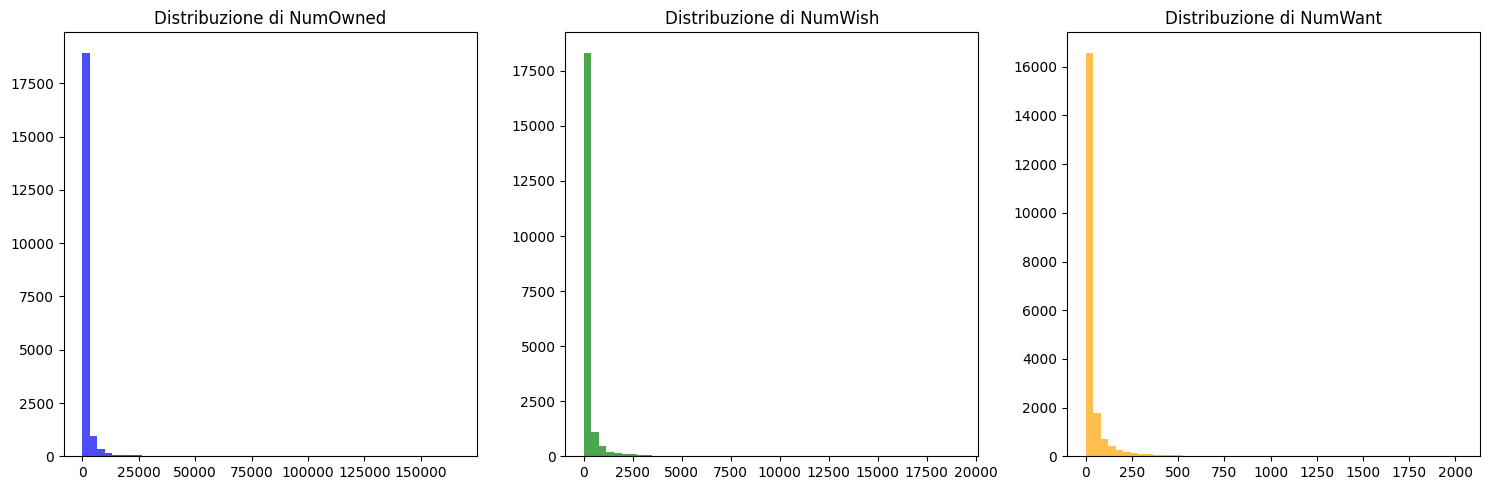

In [102]:
#vedo qual è la distribuzione di numowned, numwish, numwant
plt.figure(figsize=(15,5))
plt.subplot(1, 3, 1)
plt.hist(bf['NumOwned'], bins=50, color='blue', alpha=0.7) #alpha controlla il livello di trasparenza o opacità
plt.title('Distribuzione di NumOwned')
plt.subplot(1, 3, 2)
plt.hist(bf['NumWish'], bins=50, color='green', alpha=0.7)
plt.title('Distribuzione di NumWish')
plt.subplot(1, 3, 3)
plt.hist(bf['NumWant'], bins=50, color='orange', alpha=0.7)
plt.title('Distribuzione di NumWant')
plt.tight_layout()
plt.show()

#inutile visualizzare con istogramma o bar plot perchè i valori sono troppo concentrati in un certo range

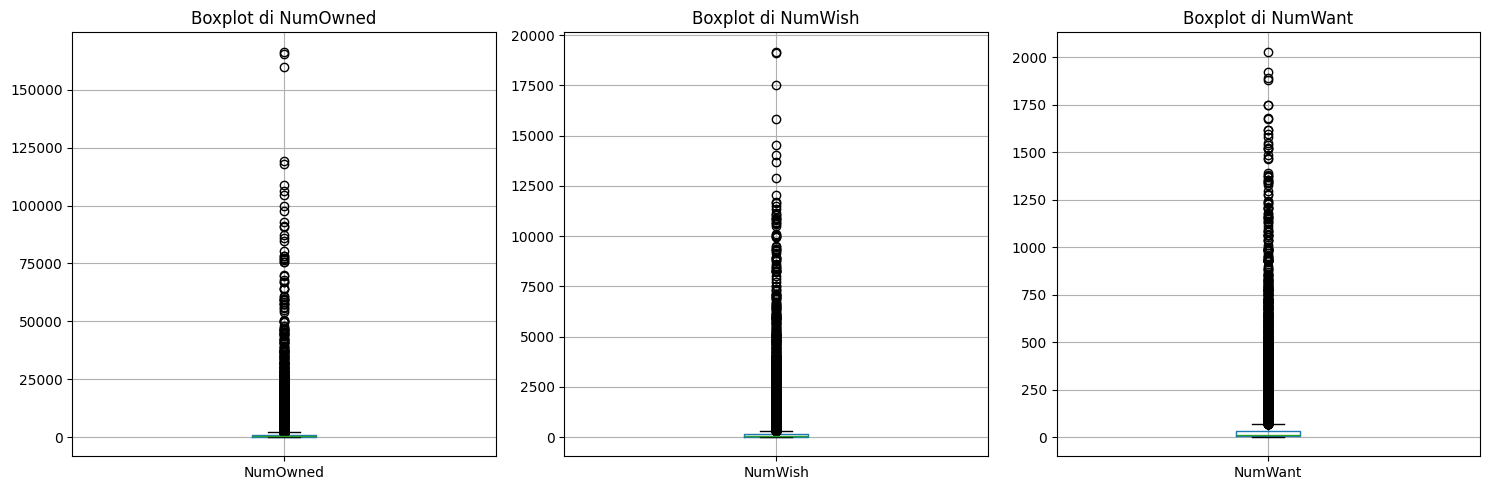

In [103]:
#boxplot di numowned, numwish, numwant
plt.figure(figsize=(15,5))
plt.subplot(1, 3, 1)
boxplot = bf.boxplot(column=['NumOwned'])
plt.title('Boxplot di NumOwned')
plt.subplot(1, 3, 2)
boxplot = bf.boxplot(column=['NumWish'])
plt.title('Boxplot di NumWish')
plt.subplot(1, 3, 3)
boxplot = bf.boxplot(column=['NumWant'])
plt.title('Boxplot di NumWant')
plt.tight_layout()
plt.show()

In [104]:
#Vedo quali giochi hanno NumOwned massimo, NumWish massimo e NumWant massimo
gioco_top_owned = bf[["NumOwned", "Name"]][bf["NumOwned"] == bf["NumOwned"].max()]
print(gioco_top_owned)

gioco_top_desideri = bf[["NumWish", "Name"]][bf["NumWish"] == bf["NumWish"].max()]
print(gioco_top_desideri)

gioco_top_want= bf[["NumWant", "Name"]][bf["NumWant"] == bf["NumWant"].max()]
print(gioco_top_want)

      NumOwned      Name
3603    166497  Pandemic
       NumWish    Name
13339    19182  Scythe
      NumWant               Name
4835     2031  Terraforming Mars


In [105]:
#correlazione tra numwish e numwant
bf['NumWish'].corr(bf['NumWant'])

np.float64(0.9396029715828205)

In [106]:
bf['NumWish'].corr(bf['NumOwned'])

np.float64(0.8028978680489295)

In [107]:
#Vista l'alta correlazione di 0,94 tra Numwant e NumWish, ritengo opportuno droppare una delle due colonne.
bf = bf.drop(columns=['NumWant'])

In [108]:
#Vedo i valori di media, mediana ecc. di NUmOwned
bf['NumOwned'].describe()

count     20773.000000
mean       1512.525490
std        5387.829836
min           2.000000
25%         156.000000
50%         337.000000
75%         946.000000
max      166497.000000
Name: NumOwned, dtype: float64

In [109]:
#Vedo i valori di media, mediana ecc. di NumWish
bf['NumWish'].describe()

count    20773.000000
mean       238.714052
std        807.734387
min          0.000000
25%         15.000000
50%         41.000000
75%        135.000000
max      19182.000000
Name: NumWish, dtype: float64

In [110]:
#Normalizzazione logaritmica di NumOwned e NumWish
bf["NumOwned"] = np.log1p(bf["NumOwned"])
bf["NumWish"] = np.log1p(bf["NumWish"])


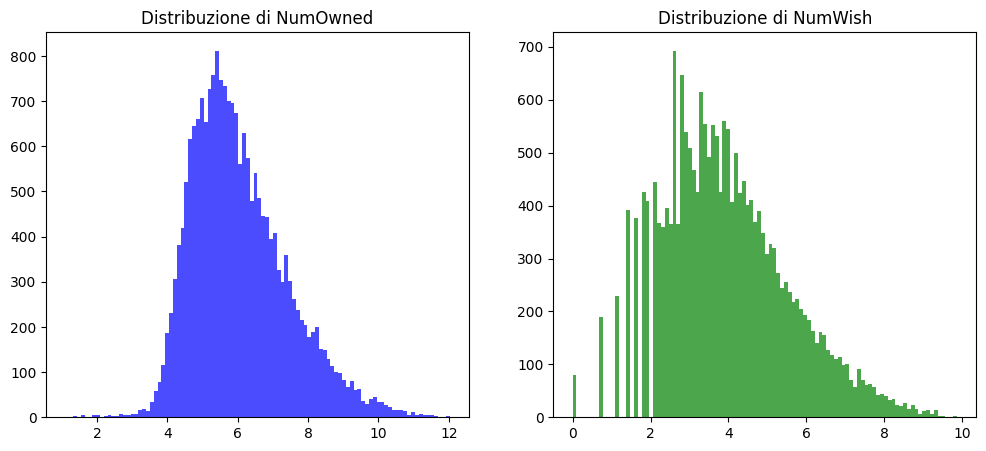

In [111]:
#Ricontrollo la distribuzione dopo la normalizzazione logaritmica
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(bf['NumOwned'], bins=100, color='blue', alpha=0.7)
plt.title('Distribuzione di NumOwned')
plt.subplot(1, 2, 2)
plt.hist(bf['NumWish'], bins=100, color='green', alpha=0.7)
plt.title('Distribuzione di NumWish')
plt.show()

In [112]:
#Controllo giochi con numowned o numwish uguale a 0
numowned = bf[bf['NumOwned'] == 0]
numwish = bf[bf['NumWish'] == 0]
len(numowned), len(numwish)
#Accettabile avere giochi con numowned o numwish uguale a 0, non sono errori, perchè sono giochi non desiderati da nessuno o che non ha nessuno

(0, 79)

###HANDLING NUMWEIGHTVOTES

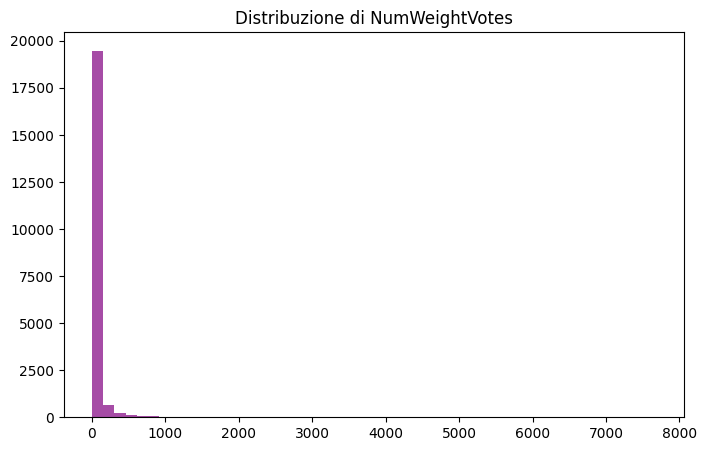

In [113]:
#Visualizzo con un grafico la distribuzione di NumWeightVotes
plt.figure(figsize=(8,5))
plt.hist(bf['NumWeightVotes'], bins=50, color='purple', alpha=0.7)
plt.title('Distribuzione di NumWeightVotes')
plt.show()

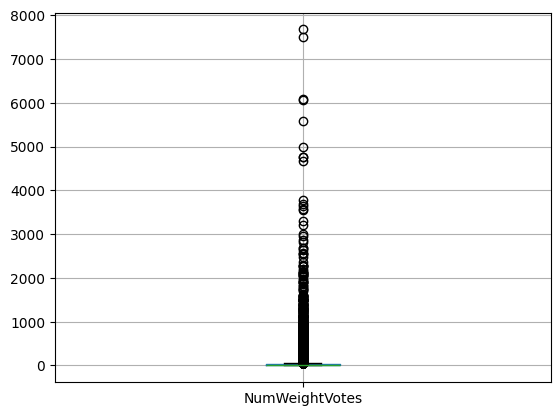

In [114]:
#boxplot di NumWeightVotes
boxplot = bf.boxplot(column=['NumWeightVotes'])

In [115]:
numweightvotes_0 = bf[bf["NumWeightVotes"] == 0]
len(numweightvotes_0)

443

In [116]:
bf["NumWeightVotes"].describe()

count    20773.000000
mean        50.541809
std        208.713147
min          0.000000
25%          4.000000
50%         10.000000
75%         27.000000
max       7673.000000
Name: NumWeightVotes, dtype: float64

In [117]:
#correlazione tra numweightvotes e numuserratings
bf["NumWeightVotes"].corr(bf["NumUserRatings"])

np.float64(0.916303023851665)

In [118]:
#normalizzazione logaritmica di NumWeightVotes
bf["NumWeightVotes"] = np.log1p(bf["NumWeightVotes"])

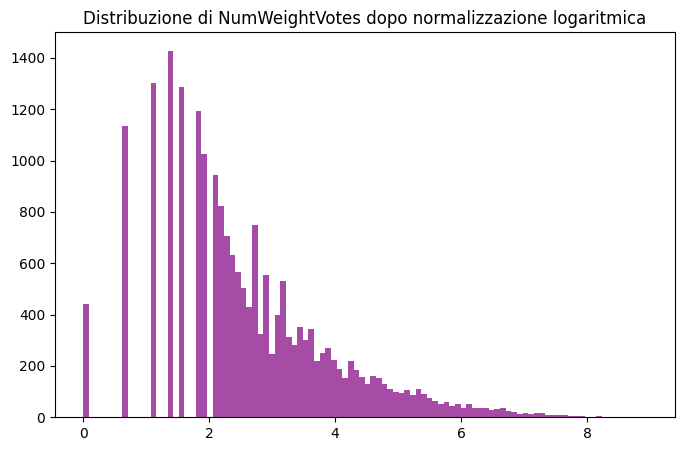

In [119]:
#ricontrollo la distribuzione dopo la normalizzazione logaritmica
plt.figure(figsize=(8,5))
plt.hist(bf['NumWeightVotes'], bins=100, color='purple', alpha=0.7)
plt.title('Distribuzione di NumWeightVotes dopo normalizzazione logaritmica')
plt.show()

In [120]:
#controllo giochi con numweightvotes uguale a 0
numweightvotes_0 = bf[bf["NumWeightVotes"] == 0]
len(numweightvotes_0)
#è accettabile avere giochi con numweightvotes uguale a 0, in quanto possono essere giochi non valutati dagli utenti

443

###HANDLING BESTPLAYERS AND GOODPLAYERS

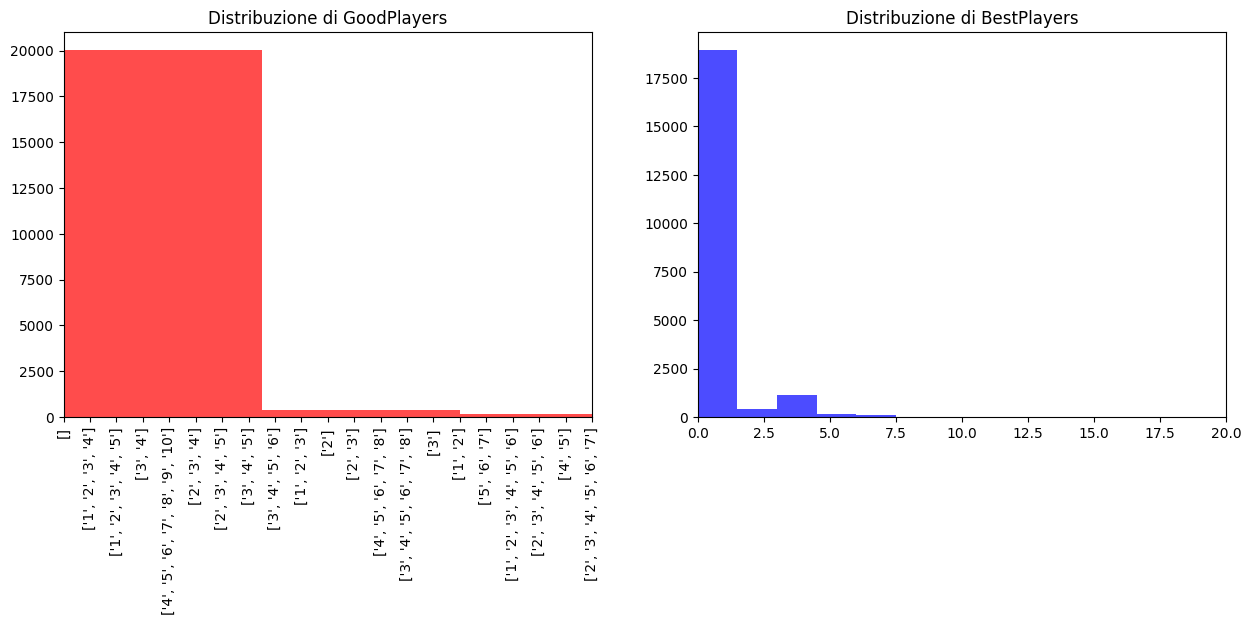

In [121]:
#Visualizzo graficamente la distribuzione di GoodPlayers e BestPlayers
plt.figure(figsize=(15,5))
plt.subplot(1, 2, 1)
plt.hist(bf['GoodPlayers'], bins=10, color='red', alpha=0.7)
plt.title('Distribuzione di GoodPlayers')
plt.xlim(0,20)
plt.xticks(rotation = 90)
plt.subplot(1, 2, 2)
plt.hist(bf['BestPlayers'], bins=10, color='blue', alpha=0.7)
plt.title('Distribuzione di BestPlayers')
plt.xlim(0,20)
plt.show()
#Da questi istogrammi capisco che goodplayers non è type integer


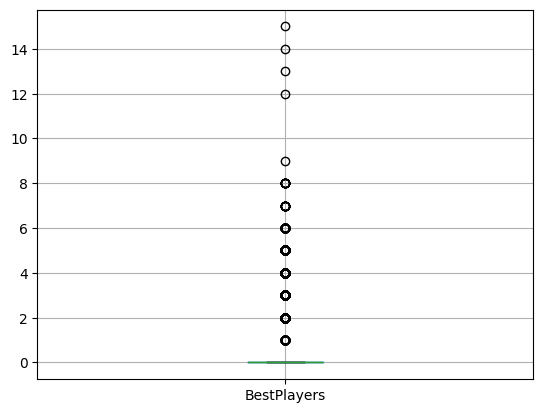

In [122]:
#boxplot di bestplayers
boxplot = bf.boxplot(column=['BestPlayers'])

In [123]:
bf["GoodPlayers"].head(100)

0      []
1      []
2      []
3      []
4      []
       ..
99     []
100    []
101    []
102    []
103    []
Name: GoodPlayers, Length: 100, dtype: object

In [124]:
#controllo quanti giochi hanno per goodplayers una lista vuota
empty_goodplayers = bf[bf['GoodPlayers'] == '[]']
len(empty_goodplayers)


18834

In [125]:
#Controllo quanti giochi hanno bestplayers uguale a 0
bestplayers_0 = bf[bf['BestPlayers'] == 0]
len(bestplayers_0)

18833

In [126]:
bf["GoodPlayers"].describe()

count     20773
unique       76
top          []
freq      18834
Name: GoodPlayers, dtype: object

In [127]:
bf["BestPlayers"].describe()

count    20773.000000
mean         0.321668
std          1.081607
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         15.000000
Name: BestPlayers, dtype: float64

In [128]:
bf["BestPlayers"].dtypes

dtype('int64')

In [129]:
#Visto che la maggior parte dei valori delle colonne GoodPlayers e BestPlayers sono vuoti o uguali a 0, decido di droppare entrambe le colonne.
bf = bf.drop(columns=['GoodPlayers', 'BestPlayers'])

###HANDLING NUMUSERRATINGS

In [130]:
bf["NumUserRatings"].dtypes

dtype('int64')

In [131]:
bf["NumUserRatings"].describe()

count     20773.000000
mean        887.987195
std        3706.621555
min          30.000000
25%          59.000000
50%         130.000000
75%         416.000000
max      108101.000000
Name: NumUserRatings, dtype: float64

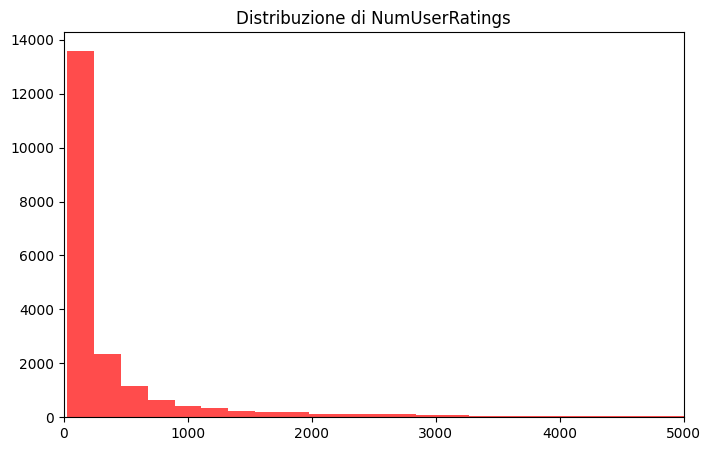

In [132]:
#vedo graficamente la distribuzione di NumUserRatings
plt.figure(figsize=(8,5))
plt.hist(bf['NumUserRatings'], bins=500, color='red', alpha=0.7)
plt.title('Distribuzione di NumUserRatings')
plt.xlim(0,5000)
plt.show()

In [133]:
bf['NumUserRatings'].max()

np.int64(108101)

In [134]:
#correlazione tra NumUserRatings e NumOwned
bf['NumUserRatings'].corr(bf['NumOwned'])

np.float64(0.5287330713273019)

In [135]:
numuserratings_0 =bf[bf["NumUserRatings"] == 0]
len(numuserratings_0)

0

In [136]:
#In virtù dell'alta correlazione tra NumUserRatings e NumOwned, per evitare ridondanza, decido di droppare la colonna NumUserRatings.
bf = bf.drop(columns=['NumUserRatings'])

In [137]:
bf = bf.drop(["NumComments","ImagePath"], axis=1)

In [138]:
# rating 

# la colonna è categorica di tipo ordinale, quindi ha senso cambiare i valori da LOW,MEDIUM,HIGH a 1,2,3
# Pulisce gli spazi bianchi prima e dopo la stringa
bf['Rating'] = bf['Rating'].str.strip()
rating_map = {
    "Low":1,
    "Medium":2,
    "High":3
}

bf["Rating"] = bf["Rating"].map(rating_map)

bf["Rating"].value_counts()





Rating
2    9277
1    6693
3    4803
Name: count, dtype: int64

Rank:strategygames
1.0       1
2.0       1
3.0       1
4.0       1
5.0       1
         ..
2324.0    1
2325.0    1
2326.0    1
2327.0    1
2328.0    1
Name: count, Length: 2311, dtype: int64
Rank:abstracts
1.0       1
2.0       1
3.0       1
4.0       1
5.0       1
         ..
1100.0    1
1102.0    1
1108.0    1
1110.0    1
1113.0    1
Name: count, Length: 999, dtype: int64
Rank:familygames
1.0       1
2.0       1
3.0       1
4.0       1
6.0       1
         ..
2308.0    1
2309.0    1
2310.0    1
2314.0    1
2316.0    1
Name: count, Length: 2252, dtype: int64
Rank:thematic
1.0       1
2.0       1
3.0       1
4.0       1
5.0       1
         ..
1224.0    1
1225.0    1
1226.0    1
1227.0    1
1228.0    1
Name: count, Length: 1218, dtype: int64
Rank:cgs
1.0      1
2.0      1
3.0      1
4.0      1
5.0      1
        ..
299.0    1
300.0    1
301.0    1
302.0    1
303.0    1
Name: count, Length: 298, dtype: int64
Rank:wargames
1.0       1
2.0       1
3.0       1
4.0       1
5.0       1
     

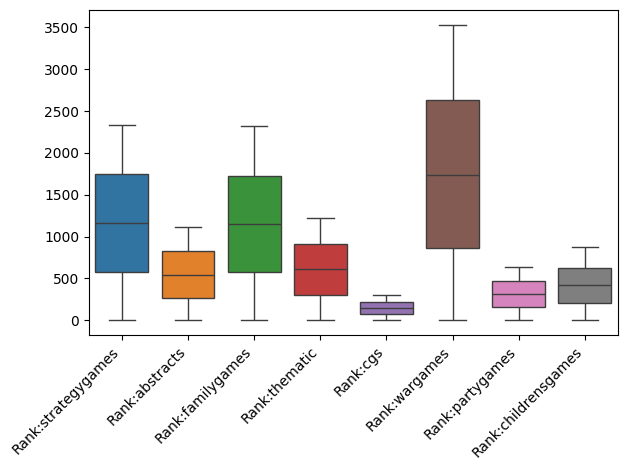

2311
999
2252
1218
298
3260
611
821


In [139]:
# ranking (tutte e 8 le colonne)
ranking =bf[['Rank:strategygames', 'Rank:abstracts', 'Rank:familygames',
       'Rank:thematic', 'Rank:cgs', 'Rank:wargames', 'Rank:partygames',
       'Rank:childrensgames']]



# sembra di capire che 21926 è un sentinel value andiamo a sostuirlo con NaN in modo da rimuovere il rumore e facilitare l'analisi
colonne_da_pulire = ['Rank:strategygames', 'Rank:abstracts', 'Rank:familygames',
       'Rank:thematic', 'Rank:cgs', 'Rank:wargames', 'Rank:partygames',
       'Rank:childrensgames']
bf[colonne_da_pulire] =bf[colonne_da_pulire].replace(21926,np.nan)

ranking.replace(21926, np.nan,inplace= True)

for e in ranking:
    print(ranking[e].value_counts().sort_index())
# ora che ho tolto tutto il rumore possiamo lavorare sui dati rimasti 

sns.boxplot(ranking)
ax = plt.gca() # 'gca' significa 'get current axes'

# Imposta la rotazione delle etichette sull'asse X
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right') 
# 'rotation=45' ruota le etichette di 45 gradi
# 'ha='right'' (horizontal alignment) le allinea a destra per evitare sovrapposizioni

# Rendi il layout più compatto per accogliere le etichette ruotate
plt.tight_layout()

# Mostra il grafico
plt.show()
for e in ranking:
    print(ranking[e].count())

In [140]:
# proviamo con il binning 

import numpy as np

# Definiamo i "tagli" per i nostri bin.
# -1 per includere lo 0 nel primo bin. np.inf è l'infinito.
bins = [
    -1, 
    0,     # Categoria 1: Solo 0
    1,     # Categoria 2: Solo 1
    5,     # Categoria 3: Da 2 a 5
    10,    # Categoria 4: Da 6 a 10
    np.inf # Categoria 5: Oltre 10
]

# Definiamo le etichette per questi bin
labels = [
    'Nessuno (0)',
    'Uno (1)',
    'Pochi (2-5)',
    'Moderati (6-10)',
    'Molti (11+)'
]

# Creiamo la nuova colonna
bf['NumAlternates'] = pd.cut(
    bf['NumAlternates'], 
    bins=bins, 
    labels=labels
)



In [141]:
bf.head(20)

,BGGId,Name,YearPublished,ComWeight,MinPlayers,MaxPlayers,ComAgeRec,LanguageEase,NumOwned,NumWish,...,Cat:Thematic,Cat:Strategy,Cat:War,Cat:Family,Cat:CGS,Cat:Abstract,Cat:Party,Cat:Childrens,Rating,perc_distance_playtime
0,140386,Assassin's Creed: Arena,2014,2.0512,2,4,8,5.365976,6.270988,4.174387,...,0,0,0,0,0,0,0,0,1,0.000000
1,344114,Bag of Chips,2021,1.2256,2,5,8,3.610918,4.290459,3.871201,...,0,0,0,0,0,0,0,0,2,9.349442
2,319196,Gùgōng: Deluxe Big Box,2020,3.8190,1,5,10,1.000000,6.727432,4.158883,...,0,0,0,0,0,0,0,0,3,37.468764
3,11404,LetterFlip,2004,1.4216,2,2,7,1.000000,5.043425,2.079442,...,0,0,0,0,0,0,0,0,1,0.000000
4,281020,Treasures of Cibola,2019,1.6230,2,4,10,2.079442,5.342334,3.583519,...,0,0,0,0,0,0,0,0,2,9.349442
5,172598,H.I.D.E.: Hidden Identity Dice Espionage,2015,1.7547,3,5,8,6.218600,6.190315,3.970292,...,0,0,0,0,0,0,0,0,1,0.000000
7,89620,Monopoly: Canada (Electronic Banking),2009,1.2785,2,6,10,1.000000,4.919981,1.386294,...,0,0,0,0,0,0,0,0,1,0.000000
8,8983,I.Q. 2000,1984,1.9372,2,6,8,3.028522,6.369901,2.302585,...,0,0,0,0,0,0,0,0,1,0.000000
9,130185,Speedy Recall,2012,1.1469,2,6,10,1.000000,4.574711,0.693147,...,0,0,0,0,0,0,0,0,2,0.000000
10,88296,BOLSA: the board game,2011,1.8334,2,6,10,1.000000,4.043051,1.386294,...,0,0,0,0,0,0,0,0,2,0.000000


In [142]:
# facciamo un one hot encoding per completare la colonna 

# 'df' è il tuo dataframe, 'NumAlternates_Binned' è la colonna che hai creato
df_encoded = pd.get_dummies(
    bf, 
    columns=['NumAlternates'], 
    drop_first=True # Utile per evitare multicollinearità
)

bf.head()

,BGGId,Name,YearPublished,ComWeight,MinPlayers,MaxPlayers,ComAgeRec,LanguageEase,NumOwned,NumWish,...,Cat:Thematic,Cat:Strategy,Cat:War,Cat:Family,Cat:CGS,Cat:Abstract,Cat:Party,Cat:Childrens,Rating,perc_distance_playtime
0,140386,Assassin's Creed: Arena,2014,2.0512,2,4,8,5.365976,6.270988,4.174387,...,0,0,0,0,0,0,0,0,1,0.000000
1,344114,Bag of Chips,2021,1.2256,2,5,8,3.610918,4.290459,3.871201,...,0,0,0,0,0,0,0,0,2,9.349442
2,319196,Gùgōng: Deluxe Big Box,2020,3.8190,1,5,10,1.000000,6.727432,4.158883,...,0,0,0,0,0,0,0,0,3,37.468764
3,11404,LetterFlip,2004,1.4216,2,2,7,1.000000,5.043425,2.079442,...,0,0,0,0,0,0,0,0,1,0.000000
4,281020,Treasures of Cibola,2019,1.6230,2,4,10,2.079442,5.342334,3.583519,...,0,0,0,0,0,0,0,0,2,9.349442


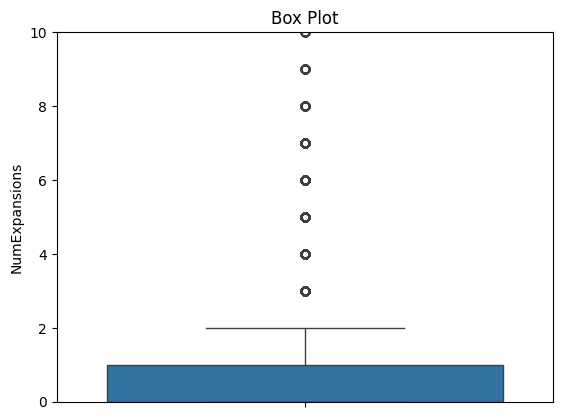

NumExpansions
0      15291
1       2366
2        959
3        488
4        357
       ...  
177        1
186        1
232        1
254        1
525        1
Name: count, Length: 98, dtype: int64

In [143]:
num_expansions = bf["NumExpansions"].value_counts()



bf["NumExpansions"].max() #525

num_expansions = bf["NumExpansions"].value_counts().sort_index()



# Ridisegna il box plot, zoomando sull'intervallo 0-10
sns.boxplot(bf["NumExpansions"])
  # Limite Y impostato a 10
plt.title("Box Plot")
plt.ylim(0,10)
plt.show()

num_expansions



In [144]:
bf["NumImplementations"] = np.log1p(bf['NumImplementations'])

bf["NumExpansions"] = np.log1p(bf["NumExpansions"])

bf.head(10)

,BGGId,Name,YearPublished,ComWeight,MinPlayers,MaxPlayers,ComAgeRec,LanguageEase,NumOwned,NumWish,...,Cat:Thematic,Cat:Strategy,Cat:War,Cat:Family,Cat:CGS,Cat:Abstract,Cat:Party,Cat:Childrens,Rating,perc_distance_playtime
0,140386,Assassin's Creed: Arena,2014,2.0512,2,4,8,5.365976,6.270988,4.174387,...,0,0,0,0,0,0,0,0,1,0.000000
1,344114,Bag of Chips,2021,1.2256,2,5,8,3.610918,4.290459,3.871201,...,0,0,0,0,0,0,0,0,2,9.349442
2,319196,Gùgōng: Deluxe Big Box,2020,3.8190,1,5,10,1.000000,6.727432,4.158883,...,0,0,0,0,0,0,0,0,3,37.468764
3,11404,LetterFlip,2004,1.4216,2,2,7,1.000000,5.043425,2.079442,...,0,0,0,0,0,0,0,0,1,0.000000
4,281020,Treasures of Cibola,2019,1.6230,2,4,10,2.079442,5.342334,3.583519,...,0,0,0,0,0,0,0,0,2,9.349442
5,172598,H.I.D.E.: Hidden Identity Dice Espionage,2015,1.7547,3,5,8,6.218600,6.190315,3.970292,...,0,0,0,0,0,0,0,0,1,0.000000
7,89620,Monopoly: Canada (Electronic Banking),2009,1.2785,2,6,10,1.000000,4.919981,1.386294,...,0,0,0,0,0,0,0,0,1,0.000000
8,8983,I.Q. 2000,1984,1.9372,2,6,8,3.028522,6.369901,2.302585,...,0,0,0,0,0,0,0,0,1,0.000000
9,130185,Speedy Recall,2012,1.1469,2,6,10,1.000000,4.574711,0.693147,...,0,0,0,0,0,0,0,0,2,0.000000
10,88296,BOLSA: the board game,2011,1.8334,2,6,10,1.000000,4.043051,1.386294,...,0,0,0,0,0,0,0,0,2,0.000000


In [145]:

bf['belong_to_family'] = bf['Family'].notna().astype(int)

bf = bf.drop("Family", axis= 1)
bf["belong_to_family"]
bf.head(5)


,BGGId,Name,YearPublished,ComWeight,MinPlayers,MaxPlayers,ComAgeRec,LanguageEase,NumOwned,NumWish,...,Cat:Strategy,Cat:War,Cat:Family,Cat:CGS,Cat:Abstract,Cat:Party,Cat:Childrens,Rating,perc_distance_playtime,belong_to_family
0,140386,Assassin's Creed: Arena,2014,2.0512,2,4,8,5.365976,6.270988,4.174387,...,0,0,0,0,0,0,0,1,0.000000,0
1,344114,Bag of Chips,2021,1.2256,2,5,8,3.610918,4.290459,3.871201,...,0,0,0,0,0,0,0,2,9.349442,0
2,319196,Gùgōng: Deluxe Big Box,2020,3.8190,1,5,10,1.000000,6.727432,4.158883,...,0,0,0,0,0,0,0,3,37.468764,0
3,11404,LetterFlip,2004,1.4216,2,2,7,1.000000,5.043425,2.079442,...,0,0,0,0,0,0,0,1,0.000000,0
4,281020,Treasures of Cibola,2019,1.6230,2,4,10,2.079442,5.342334,3.583519,...,0,0,0,0,0,0,0,2,9.349442,0


In [146]:
bf.head(10)





,BGGId,Name,YearPublished,ComWeight,MinPlayers,MaxPlayers,ComAgeRec,LanguageEase,NumOwned,NumWish,...,Cat:Strategy,Cat:War,Cat:Family,Cat:CGS,Cat:Abstract,Cat:Party,Cat:Childrens,Rating,perc_distance_playtime,belong_to_family
0,140386,Assassin's Creed: Arena,2014,2.0512,2,4,8,5.365976,6.270988,4.174387,...,0,0,0,0,0,0,0,1,0.000000,0
1,344114,Bag of Chips,2021,1.2256,2,5,8,3.610918,4.290459,3.871201,...,0,0,0,0,0,0,0,2,9.349442,0
2,319196,Gùgōng: Deluxe Big Box,2020,3.8190,1,5,10,1.000000,6.727432,4.158883,...,0,0,0,0,0,0,0,3,37.468764,0
3,11404,LetterFlip,2004,1.4216,2,2,7,1.000000,5.043425,2.079442,...,0,0,0,0,0,0,0,1,0.000000,0
4,281020,Treasures of Cibola,2019,1.6230,2,4,10,2.079442,5.342334,3.583519,...,0,0,0,0,0,0,0,2,9.349442,0
5,172598,H.I.D.E.: Hidden Identity Dice Espionage,2015,1.7547,3,5,8,6.218600,6.190315,3.970292,...,0,0,0,0,0,0,0,1,0.000000,0
7,89620,Monopoly: Canada (Electronic Banking),2009,1.2785,2,6,10,1.000000,4.919981,1.386294,...,0,0,0,0,0,0,0,1,0.000000,1
8,8983,I.Q. 2000,1984,1.9372,2,6,8,3.028522,6.369901,2.302585,...,0,0,0,0,0,0,0,1,0.000000,1
9,130185,Speedy Recall,2012,1.1469,2,6,10,1.000000,4.574711,0.693147,...,0,0,0,0,0,0,0,2,0.000000,0
10,88296,BOLSA: the board game,2011,1.8334,2,6,10,1.000000,4.043051,1.386294,...,0,0,0,0,0,0,0,2,0.000000,0


In [147]:
bf.to_csv('../data/processed/board_games_clean.csv', index=False)

In [148]:
bf_clean = pd.read_csv('../data/processed/board_games_clean.csv')

In [149]:
#controllo quanti Nan ci sono nelle colonne Rank: in bf_clean
rank_columns = [col for col in bf_clean.columns if col.startswith('Rank:')]
nan_counts = bf_clean[rank_columns].isna().sum()
print("Number of NaN values in Rank columns:")
print(nan_counts)

Number of NaN values in Rank columns:
Rank:strategygames     18462
Rank:abstracts         19774
Rank:familygames       18521
Rank:thematic          19555
Rank:cgs               20475
Rank:wargames          17513
Rank:partygames        20162
Rank:childrensgames    19952
dtype: int64


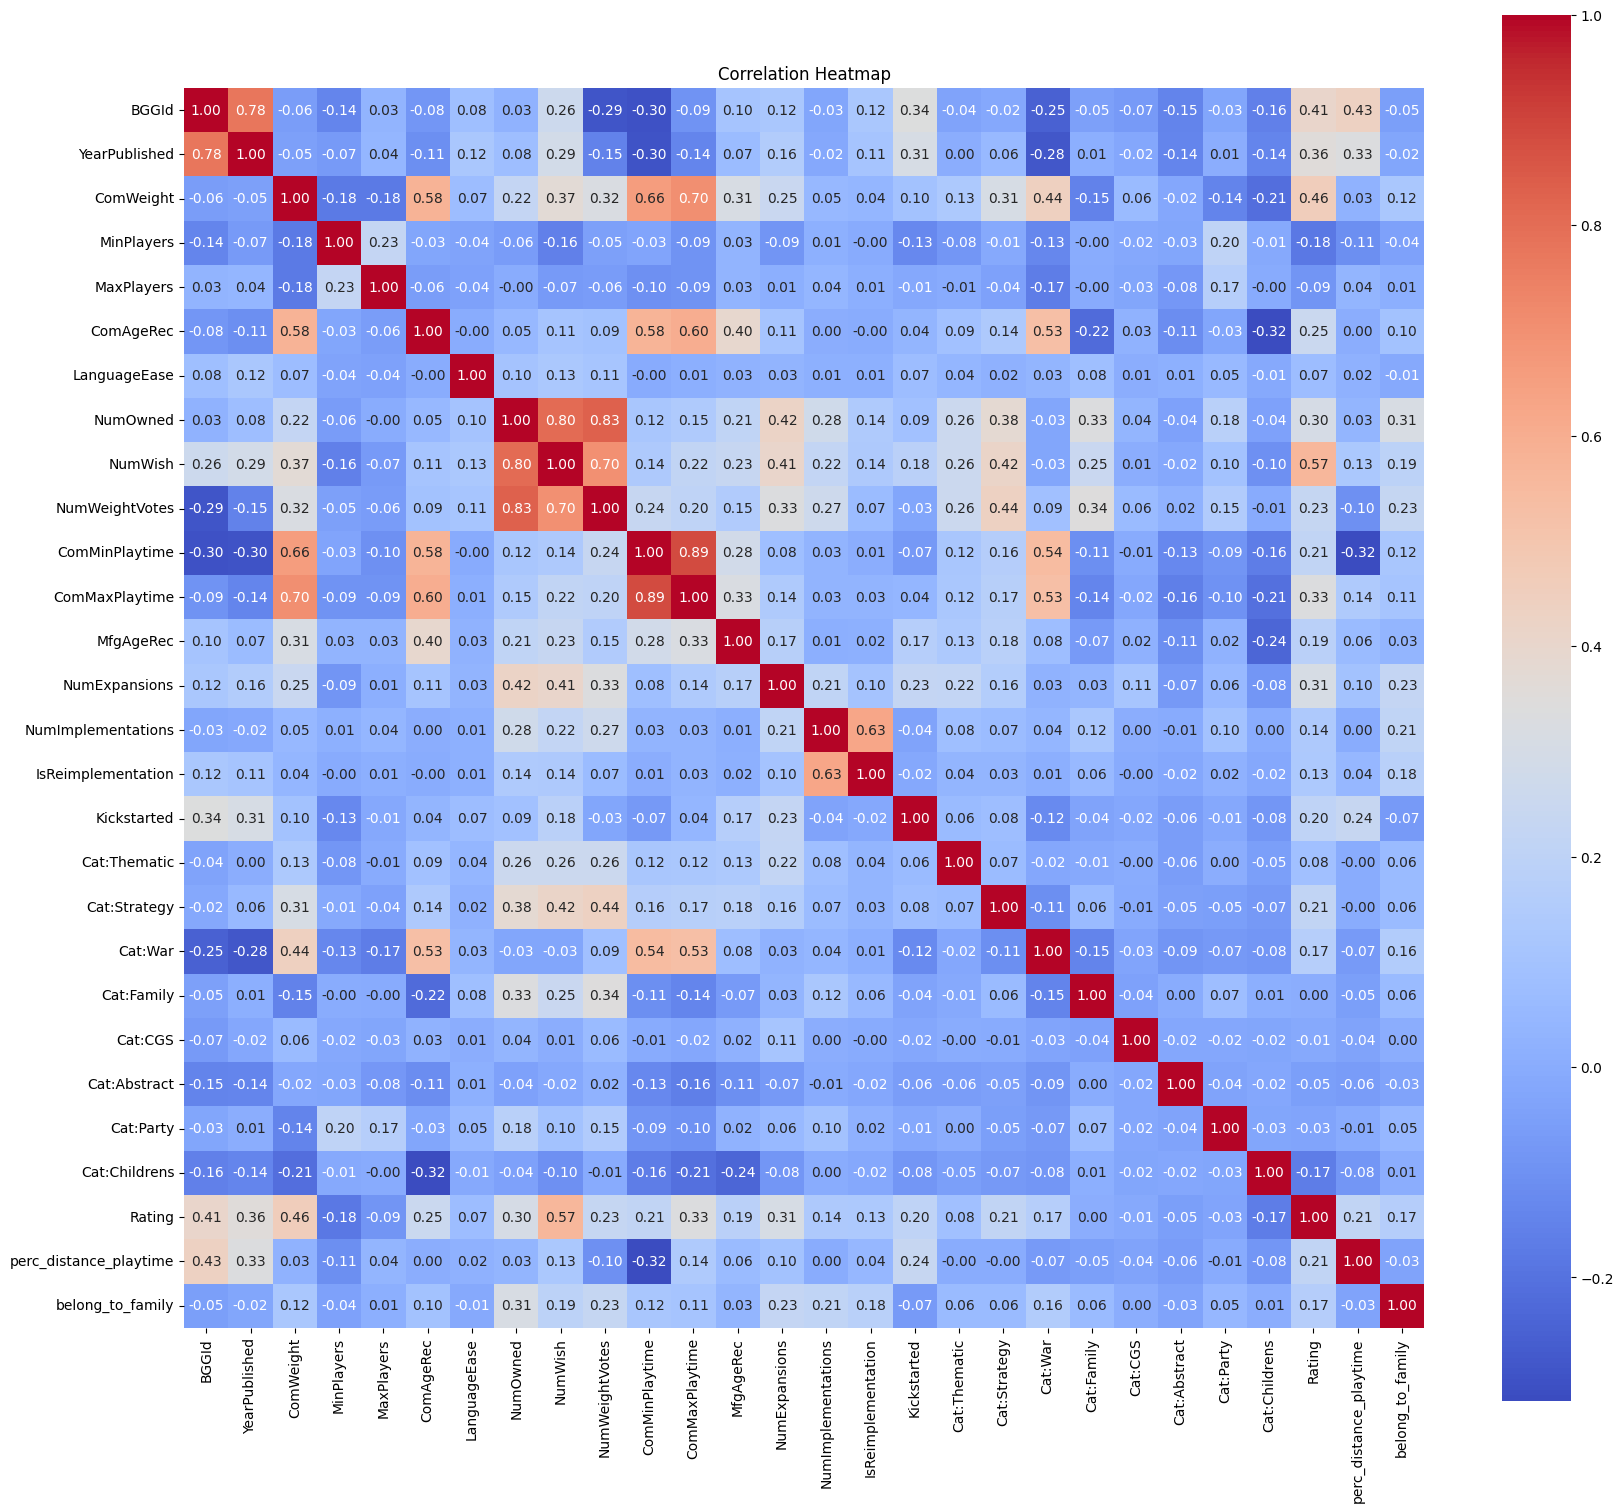

In [155]:
#heatmap senza le colonne Rank e solo valori numerici
numeric_cols = bf_clean.select_dtypes(include=['number']).drop(columns=rank_columns)
plt.figure(figsize=(20, 18))
correlation_matrix = numeric_cols.corr()
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True)
plt.title('Correlation Heatmap')
plt.show()
